<a href="https://colab.research.google.com/github/naurahzahiyah/Naurah-Nur-ZAHIYAH/blob/main/FIX_Olist_Customer_Churn_Prediction_%26_Sales%E2%80%93Marketing_Dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Olist Customer Churn Prediction & Sales–Marketing Dashboard

Alur: fact table order-level → customer features → preprocessing tanpa leakage → 3 model machine learning → 1 deep learning → evaluasi → EDA, RFM, dan dataset dashboard.

**Definisi churn:** pelanggan yang bertransaksi pada feature window tetapi tidak kembali pada label month diberi label `is_churn = 1`. Karena Olist memiliki repeat purchase yang sangat rendah, evaluasi tidak hanya memakai accuracy, tetapi juga balanced accuracy, ROC-AUC, PR-AUC, recall pelanggan aktif, MCC, classification report, dan confusion matrix.


## 1. Import library dan konfigurasi

Untuk uji cepat, ubah `FINAL_RUN = False`. Untuk hasil final, biarkan `True`.


In [ ]:
from pathlib import Path
import random
import shutil
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option(
    "display.max_columns",
    100
)

pd.set_option(
    "display.max_rows",
    100
)

sns.set_theme(
    style="whitegrid"
)

# Random seed agar hasil dapat direproduksi
SEED = 42

np.random.seed(SEED)
random.seed(SEED)

# Folder kerja Google Colab
BASE_DIR = Path("/content")
RAW_DIR = BASE_DIR

DATA_DIR = (
    BASE_DIR / "olist_data"
)

OUTPUT_DIR = (
    BASE_DIR / "olist_outputs"
)

FIG_DIR = (
    OUTPUT_DIR / "figures"
)

MODEL_DIR = (
    OUTPUT_DIR / "models"
)

for folder in [
    DATA_DIR,
    OUTPUT_DIR,
    FIG_DIR,
    MODEL_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

# True  = proses final
# False = uji coba lebih cepat
FINAL_RUN = True

N_ITER_ML = (
    5 if FINAL_RUN else 2
)

N_TRIALS_DL = (
    4 if FINAL_RUN else 2
)

MAX_EPOCHS = (
    25 if FINAL_RUN else 5
)

configuration_table = pd.DataFrame({
    "Pengaturan": [
        "Mode",
        "Random seed",
        "Folder data",
        "Folder output",
        "ML Random Search",
        "DL Random Search",
        "Maksimal epoch"
    ],
    "Nilai": [
        (
            "Final"
            if FINAL_RUN
            else "Quick Test"
        ),
        SEED,
        str(DATA_DIR),
        str(OUTPUT_DIR),
        N_ITER_ML,
        N_TRIALS_DL,
        MAX_EPOCHS
    ]
})

display(configuration_table)

,Pengaturan,Nilai
0,Mode,Final
1,Random seed,42
2,Folder data,/content/olist_data
3,Folder output,/content/olist_outputs
4,ML Random Search,5
5,DL Random Search,4
6,Maksimal epoch,25


## 2. Upload dan validasi dataset

In [ ]:
required_files = [
    "olist_customers_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv"
]

# Memeriksa file yang sudah tersedia
missing_files = [
    filename
    for filename in required_files
    if not (
        RAW_DIR / filename
    ).exists()
]

# Upload hanya jika ada file yang belum tersedia
if missing_files:

    print(
        "File berikut belum tersedia:"
    )

    for filename in missing_files:
        print("-", filename)

    print(
        "\nSilakan upload file tersebut."
    )

    files.upload()

# Pemeriksaan ulang setelah upload
missing_files = [
    filename
    for filename in required_files
    if not (
        RAW_DIR / filename
    ).exists()
]

if missing_files:
    raise FileNotFoundError(
        "File berikut masih belum tersedia:\n"
        + "\n".join(missing_files)
    )

file_inventory = pd.DataFrame([
    {
        "Nama File": filename,
        "Status": "Tersedia",
        "Ukuran (MB)": round(
            (
                RAW_DIR / filename
            ).stat().st_size
            / 1_048_576,
            2
        )
    }
    for filename in required_files
])

display(file_inventory)

print(
    "Seluruh dataset berhasil ditemukan."
)

File berikut belum tersedia:
- olist_customers_dataset.csv
- olist_orders_dataset.csv
- olist_order_items_dataset.csv
- olist_order_payments_dataset.csv
- olist_order_reviews_dataset.csv
- olist_products_dataset.csv
- product_category_name_translation.csv

Silakan upload file tersebut.


Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv


,Nama File,Status,Ukuran (MB)
0,olist_customers_dataset.csv,Tersedia,8.62
1,olist_orders_dataset.csv,Tersedia,16.84
2,olist_order_items_dataset.csv,Tersedia,14.72
3,olist_order_payments_dataset.csv,Tersedia,5.51
4,olist_order_reviews_dataset.csv,Tersedia,13.78
5,olist_products_dataset.csv,Tersedia,2.27
6,product_category_name_translation.csv,Tersedia,0.00


Seluruh dataset berhasil ditemukan.


## 3. Load seluruh dataset

In [ ]:
customers = pd.read_csv(
    RAW_DIR
    / "olist_customers_dataset.csv"
)

orders = pd.read_csv(
    RAW_DIR
    / "olist_orders_dataset.csv"
)

items = pd.read_csv(
    RAW_DIR
    / "olist_order_items_dataset.csv"
)

payments = pd.read_csv(
    RAW_DIR
    / "olist_order_payments_dataset.csv"
)

reviews = pd.read_csv(
    RAW_DIR
    / "olist_order_reviews_dataset.csv"
)

products = pd.read_csv(
    RAW_DIR
    / "olist_products_dataset.csv"
)

category_translation = pd.read_csv(
    RAW_DIR
    / "product_category_name_translation.csv"
)

# Mengubah kolom tanggal menjadi datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

dataset_summary = pd.DataFrame([
    {
        "Dataset": "Customers",
        "Jumlah Baris": len(customers),
        "Jumlah Kolom": customers.shape[1]
    },
    {
        "Dataset": "Orders",
        "Jumlah Baris": len(orders),
        "Jumlah Kolom": orders.shape[1]
    },
    {
        "Dataset": "Order Items",
        "Jumlah Baris": len(items),
        "Jumlah Kolom": items.shape[1]
    },
    {
        "Dataset": "Payments",
        "Jumlah Baris": len(payments),
        "Jumlah Kolom": payments.shape[1]
    },
    {
        "Dataset": "Reviews",
        "Jumlah Baris": len(reviews),
        "Jumlah Kolom": reviews.shape[1]
    },
    {
        "Dataset": "Products",
        "Jumlah Baris": len(products),
        "Jumlah Kolom": products.shape[1]
    },
    {
        "Dataset": "Category Translation",
        "Jumlah Baris": len(category_translation),
        "Jumlah Kolom": category_translation.shape[1]
    }
])

display(dataset_summary)

print("Preview dataset orders:")

display(
    orders.head()
)

print("Preview dataset products:")

display(
    products.head()
)

,Dataset,Jumlah Baris,Jumlah Kolom
0,Customers,99441,5
1,Orders,99441,8
2,Order Items,112650,7
3,Payments,103886,5
4,Reviews,99224,7
5,Products,32951,9
6,Category Translation,71,2


Preview dataset orders:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


Preview dataset products:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


## 4. Data understanding dan pemeriksaan awal

,Dataset,Jumlah Baris,Jumlah Kolom,Total Missing Value,Baris Duplikat Penuh
0,Customers,99441,5,0,0
1,Orders,99441,8,4908,0
2,Order Items,112650,7,0,0
3,Payments,103886,5,0,0
4,Reviews,99224,7,145903,0
5,Products,32951,9,2448,0
6,Category Translation,71,2,0,0


,order_status,total_orders,percentage
0,delivered,96478,0.970203
1,shipped,1107,0.011132
2,canceled,625,0.006285
3,unavailable,609,0.006124
4,invoiced,314,0.003158
5,processing,301,0.003027
6,created,5,0.000050
7,approved,2,0.000020


,Indikator,Nilai
0,Tanggal transaksi paling awal,2016-09-04 21:15:19
1,Tanggal transaksi paling akhir,2018-10-17 17:30:18
2,Jumlah order unik,99441
3,Jumlah customer_id,99441
4,Jumlah customer_unique_id,96096


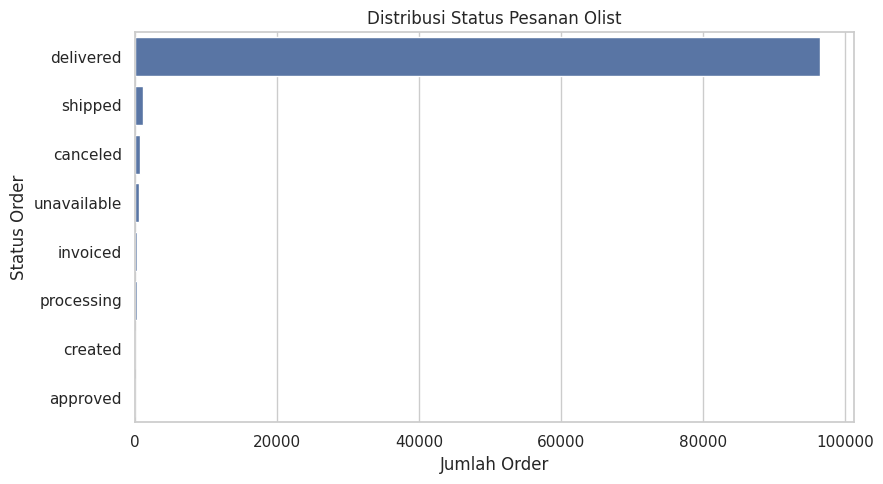

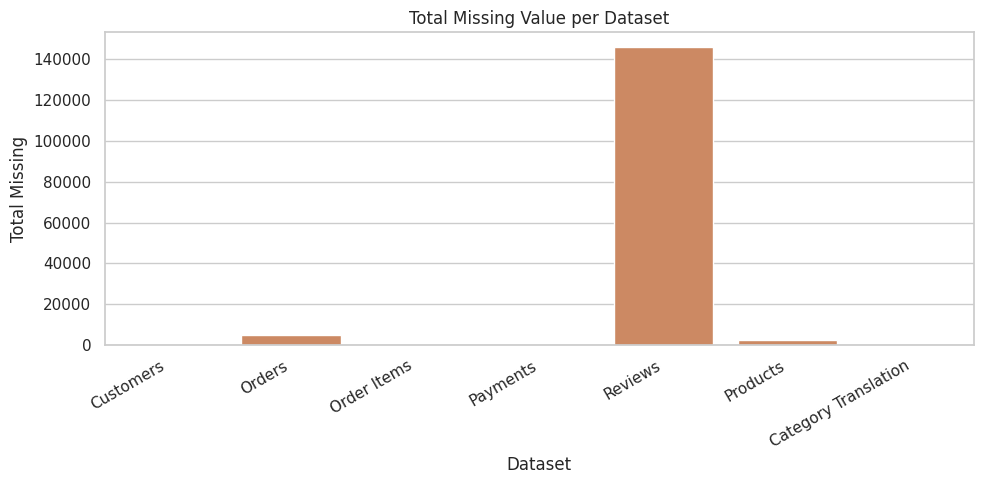

In [ ]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Category Translation":
    category_translation
}

quality_rows = []

for dataset_name, dataframe in datasets.items():

    quality_rows.append({
        "Dataset": dataset_name,
        "Jumlah Baris": len(dataframe),
        "Jumlah Kolom": dataframe.shape[1],
        "Total Missing Value":
        int(
            dataframe
            .isna()
            .sum()
            .sum()
        ),
        "Baris Duplikat Penuh":
        int(
            dataframe
            .duplicated()
            .sum()
        )
    })

data_quality_summary = pd.DataFrame(
    quality_rows
)

display(data_quality_summary)

# Pemeriksaan order status
order_status_summary = (
    orders["order_status"]
    .value_counts()
    .rename_axis("order_status")
    .reset_index(name="total_orders")
)

order_status_summary[
    "percentage"
] = (
    order_status_summary[
        "total_orders"
    ]
    / order_status_summary[
        "total_orders"
    ].sum()
)

display(order_status_summary)

# Rentang waktu transaksi
date_summary = pd.DataFrame({
    "Indikator": [
        "Tanggal transaksi paling awal",
        "Tanggal transaksi paling akhir",
        "Jumlah order unik",
        "Jumlah customer_id",
        "Jumlah customer_unique_id"
    ],
    "Nilai": [
        orders[
            "order_purchase_timestamp"
        ].min(),

        orders[
            "order_purchase_timestamp"
        ].max(),

        orders[
            "order_id"
        ].nunique(),

        customers[
            "customer_id"
        ].nunique(),

        customers[
            "customer_unique_id"
        ].nunique()
    ]
})

display(date_summary)

# Grafik order status
plt.figure(figsize=(9, 5))

sns.barplot(
    data=order_status_summary,
    y="order_status",
    x="total_orders",
    color="#4C72B0"
)

plt.title(
    "Distribusi Status Pesanan Olist"
)

plt.xlabel("Jumlah Order")
plt.ylabel("Status Order")
plt.tight_layout()
plt.show()

# Missing value setiap tabel
missing_by_dataset = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Total Missing": [
        dataframe.isna().sum().sum()
        for dataframe in datasets.values()
    ]
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing_by_dataset,
    x="Dataset",
    y="Total Missing",
    color="#DD8452"
)

plt.title(
    "Total Missing Value per Dataset"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

## 5. Agregasi order items

In [ ]:
products_enriched = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

products_enriched[
    "product_category_name_english"
] = products_enriched[
    "product_category_name_english"
].fillna("unknown")

items_enriched = items.merge(
    products_enriched[
        [
            "product_id",
            "product_category_name_english"
        ]
    ],
    on="product_id",
    how="left"
)

items_enriched[
    "product_category_name_english"
] = items_enriched[
    "product_category_name_english"
].fillna("unknown")

# Satu baris per order
item_aggregation = (
    items_enriched
    .groupby("order_id", as_index=False)
    .agg(
        total_items=("order_item_id", "count"),
        items_price=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
)

item_aggregation["order_total_value"] = (
    item_aggregation["items_price"]
    + item_aggregation["freight_value"]
)

# Kategori utama berdasarkan nilai produk terbesar
category_value = (
    items_enriched
    .groupby(
        [
            "order_id",
            "product_category_name_english"
        ],
        as_index=False
    )["price"]
    .sum()
    .sort_values(
        ["order_id", "price"],
        ascending=[True, False]
    )
    .drop_duplicates("order_id")
    .rename(
        columns={
            "product_category_name_english":
            "order_main_category"
        }
    )
    [
        [
            "order_id",
            "order_main_category"
        ]
    ]
)

item_summary = pd.DataFrame({
    "Indikator": [
        "Baris order items awal",
        "Order unik setelah agregasi",
        "Rata-rata item per order",
        "Total harga produk",
        "Total freight",
        "Total nilai order"
    ],
    "Nilai": [
        len(items),
        item_aggregation["order_id"].nunique(),
        item_aggregation["total_items"].mean(),
        item_aggregation["items_price"].sum(),
        item_aggregation["freight_value"].sum(),
        item_aggregation["order_total_value"].sum()
    ]
})

display(item_summary)
display(item_aggregation.head(10))
display(category_value.head(10))

,Indikator,Nilai
0,Baris order items awal,1.126500e+05
1,Order unik setelah agregasi,9.866600e+04
2,Rata-rata item per order,1.141731e+00
3,Total harga produk,1.359164e+07
4,Total freight,2.251910e+06
5,Total nilai order,1.584355e+07


,order_id,total_items,items_price,freight_value,order_total_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,218.04
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,21.90,12.69,34.59
6,00054e8431b9d7675808bcb819fb4a32,1,19.90,11.85,31.75
7,000576fe39319847cbb9d288c5617fa6,1,810.00,70.75,880.75
8,0005a1a1728c9d785b8e2b08b904576c,1,145.95,11.65,157.60
9,0005f50442cb953dcd1d21e1fb923495,1,53.99,11.40,65.39


,order_id,order_main_category
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,pet_shop
2,000229ec398224ef6ca0657da4fc703e,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,garden_tools
5,00048cc3ae777c65dbb7d2a0634bc1ea,housewares
6,00054e8431b9d7675808bcb819fb4a32,telephony
7,000576fe39319847cbb9d288c5617fa6,garden_tools
8,0005a1a1728c9d785b8e2b08b904576c,health_beauty
9,0005f50442cb953dcd1d21e1fb923495,books_technical


## 6. Agregasi payment dan review

,order_id,payment_value_total
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04
5,00048cc3ae777c65dbb7d2a0634bc1ea,34.59
6,00054e8431b9d7675808bcb819fb4a32,31.75
7,000576fe39319847cbb9d288c5617fa6,880.75
8,0005a1a1728c9d785b8e2b08b904576c,157.60
9,0005f50442cb953dcd1d21e1fb923495,65.39


,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0
5,00048cc3ae777c65dbb7d2a0634bc1ea,4.0
6,00054e8431b9d7675808bcb819fb4a32,4.0
7,000576fe39319847cbb9d288c5617fa6,5.0
8,0005a1a1728c9d785b8e2b08b904576c,1.0
9,0005f50442cb953dcd1d21e1fb923495,4.0


,payment_type,total_orders
0,credit_card,74935
1,boleto,19784
2,voucher,3191
3,debit_card,1527
4,not_defined,3


,review_score,total_orders
0,1.0,11316
1,2.0,3167
2,3.0,8137
3,4.0,19098
4,5.0,56955


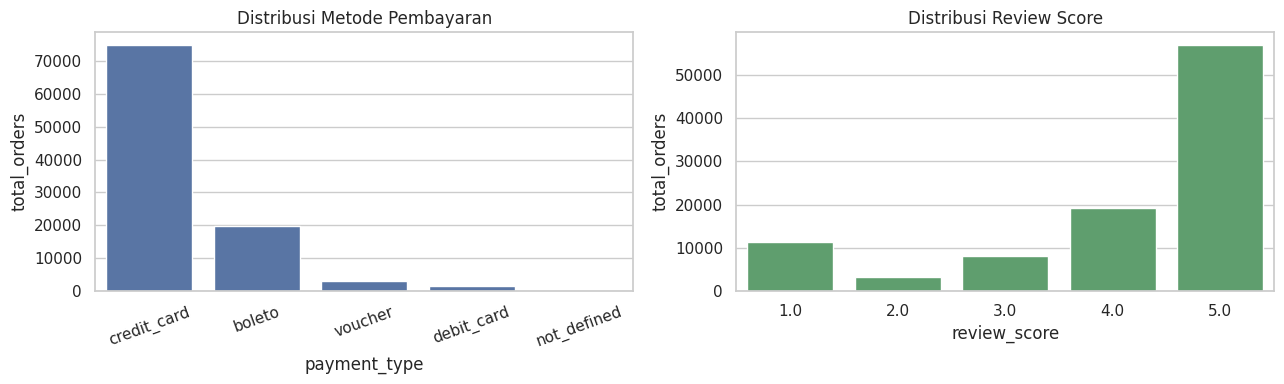

In [ ]:
# Total pembayaran per order
payment_total = (
    payments
    .groupby("order_id", as_index=False)
    ["payment_value"]
    .sum()
    .rename(
        columns={
            "payment_value":
            "payment_value_total"
        }
    )
)

# Metode pembayaran dominan
payment_main = (
    payments
    .groupby(
        [
            "order_id",
            "payment_type"
        ],
        as_index=False
    )["payment_value"]
    .sum()
    .sort_values(
        ["order_id", "payment_value"],
        ascending=[True, False]
    )
    .drop_duplicates("order_id")
    [
        [
            "order_id",
            "payment_type"
        ]
    ]
)

# Rata-rata review per order
review_aggregation = (
    reviews
    .groupby("order_id", as_index=False)
    .agg(
        review_score=("review_score", "mean")
    )
)

payment_distribution = (
    payment_main["payment_type"]
    .value_counts()
    .rename_axis("payment_type")
    .reset_index(name="total_orders")
)

review_distribution = (
    review_aggregation["review_score"]
    .round()
    .value_counts()
    .sort_index()
    .rename_axis("review_score")
    .reset_index(name="total_orders")
)

display(payment_total.head(10))
display(review_aggregation.head(10))
display(payment_distribution)
display(review_distribution)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4)
)

sns.barplot(
    data=payment_distribution,
    x="payment_type",
    y="total_orders",
    color="#4C72B0",
    ax=axes[0]
)

axes[0].set_title(
    "Distribusi Metode Pembayaran"
)

axes[0].tick_params(
    axis="x",
    rotation=20
)

sns.barplot(
    data=review_distribution,
    x="review_score",
    y="total_orders",
    color="#55A868",
    ax=axes[1]
)

axes[1].set_title(
    "Distribusi Review Score"
)

plt.tight_layout()
plt.show()

## 7. Order-level fact table

In [ ]:
fact = (
    orders
    .merge(
        customers[
            [
                "customer_id",
                "customer_unique_id",
                "customer_city",
                "customer_state"
            ]
        ],
        on="customer_id",
        how="left"
    )
    .merge(
        item_aggregation,
        on="order_id",
        how="left"
    )
    .merge(
        category_value,
        on="order_id",
        how="left"
    )
    .merge(
        payment_total,
        on="order_id",
        how="left"
    )
    .merge(
        payment_main,
        on="order_id",
        how="left"
    )
    .merge(
        review_aggregation,
        on="order_id",
        how="left"
    )
)

# Hanya transaksi yang berhasil diselesaikan
fact = fact[
    (fact["order_status"] == "delivered")
    & fact["customer_unique_id"].notna()
    & fact["order_total_value"].notna()
    & fact["order_purchase_timestamp"].notna()
].copy()

fact["order_main_category"] = (
    fact["order_main_category"]
    .fillna("unknown")
)

fact["payment_type"] = (
    fact["payment_type"]
    .fillna("unknown")
)

fact["order_month"] = (
    fact["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

fact = (
    fact
    .sort_values("order_purchase_timestamp")
    .reset_index(drop=True)
)

# Pemeriksaan level data
assert fact["order_id"].is_unique, (
    "Masih terdapat order_id duplikat."
)

assert (
    fact["order_status"] == "delivered"
).all(), (
    "Masih terdapat transaksi selain delivered."
)

fact.to_csv(
    DATA_DIR / "order_fact_table.csv",
    index=False
)

fact.to_csv(
    OUTPUT_DIR
    / "sales_dashboard_order_level.csv",
    index=False
)

fact_summary = pd.DataFrame({
    "Indikator": [
        "Total order selesai",
        "Customer unik",
        "Total sales",
        "Average order value",
        "Rata-rata review",
        "Tanggal awal",
        "Tanggal akhir"
    ],
    "Nilai": [
        fact["order_id"].nunique(),
        fact["customer_unique_id"].nunique(),
        fact["order_total_value"].sum(),
        fact["order_total_value"].mean(),
        fact["review_score"].mean(),
        fact["order_purchase_timestamp"].min(),
        fact["order_purchase_timestamp"].max()
    ]
})

display(fact_summary)

display(
    fact[
        [
            "order_id",
            "customer_unique_id",
            "order_purchase_timestamp",
            "total_items",
            "order_total_value",
            "order_main_category",
            "payment_type",
            "review_score"
        ]
    ].head(10)
)

,Indikator,Nilai
0,Total order selesai,96478
1,Customer unik,93358
2,Total sales,15419773.75
3,Average order value,159.826839
4,Rata-rata review,4.156187
5,Tanggal awal,2016-09-15 12:16:38
6,Tanggal akhir,2018-08-29 15:00:37


,order_id,customer_unique_id,order_purchase_timestamp,total_items,order_total_value,order_main_category,payment_type,review_score
0,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,2016-09-15 12:16:38,3.0,143.46,health_beauty,unknown,1.0
1,3b697a20d9e427646d92567910af6d57,32ea3bdedab835c3aa6cb68ce66565ef,2016-10-03 09:44:50,1.0,45.46,watches_gifts,boleto,4.0
2,be5bc2f0da14d8071e2d45451ad119d9,2f64e403852e6893ae37485d5fcacdaf,2016-10-03 16:56:50,1.0,39.09,sports_leisure,boleto,4.0
3,a41c8759fbe7aab36ea07e038b2d4465,61db744d2f835035a5625b59350c6b63,2016-10-03 21:13:36,1.0,53.73,sports_leisure,boleto,3.0
4,d207cc272675637bfed0062edffd0818,8d3a54507421dbd2ce0a1d58046826e0,2016-10-03 22:06:03,1.0,133.46,furniture_decor,credit_card,1.0
5,cd3b8574c82b42fc8129f6d502690c3e,87776adb449c551e74c13fc34f036105,2016-10-03 22:31:31,1.0,40.95,fashion_shoes,credit_card,5.0
6,ae8a60e4b03c5a4ba9ca0672c164b181,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,1.0,154.57,toys,credit_card,5.0
7,ef1b29b591d31d57c0d7337460dd83c9,10e89fd8e5c745f81bec101207ba4d7d,2016-10-03 22:51:30,1.0,92.27,furniture_decor,credit_card,1.0
8,0a0837a5eee9e7a9ce2b1fa831944d27,cd5a5843d35eebdf90368bf24d4a04cf,2016-10-04 09:06:10,1.0,65.50,unknown,debit_card,5.0
9,1ff217aa612f6cd7c4255c9bfe931c8b,14359ea0c7a105749c0a56478825b015,2016-10-04 09:16:33,1.0,44.23,consoles_games,credit_card,5.0


## 8. EDA fact table

,order_month,total_orders,total_customers,total_sales,average_order_value
11,2017-09,4150,4083,701077.49,168.934335
12,2017-10,4478,4417,751117.01,167.734929
13,2017-11,7289,7183,1153364.20,158.233530
14,2017-12,5513,5450,843078.29,152.925502
15,2018-01,7069,6974,1077887.46,152.480897
16,2018-02,6555,6400,966168.41,147.394113
17,2018-03,7003,6914,1120598.24,160.016884
18,2018-04,6798,6744,1132878.93,166.648857
19,2018-05,6749,6693,1128774.52,167.250633
20,2018-06,6099,6061,1011978.29,165.925281


,order_main_category,total_orders,total_sales,average_review
43,health_beauty,8614,1413225.63,4.233057
71,watches_gifts,5477,1265328.87,4.123414
7,bed_bath_table,9206,1232860.53,4.007463
65,sports_leisure,7492,1117500.98,4.234962
15,computers_accessories,6513,1034600.34,4.082228
39,furniture_decor,6190,877326.30,4.078125
49,housewares,5680,757673.37,4.206341
20,cool_stuff,3528,691578.88,4.230286
5,auto,3792,669591.94,4.153153
42,garden_tools,3407,565312.70,4.195691


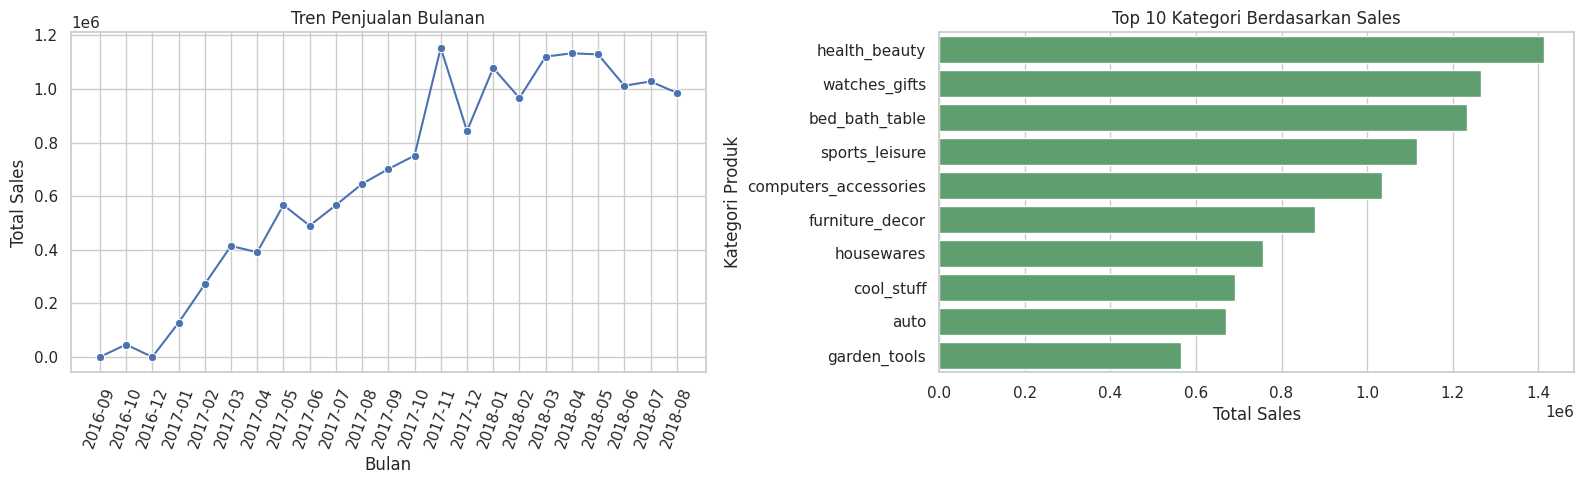

In [ ]:
monthly_transaction = (
    fact
    .groupby("order_month", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_customers=(
            "customer_unique_id",
            "nunique"
        ),
        total_sales=(
            "order_total_value",
            "sum"
        ),
        average_order_value=(
            "order_total_value",
            "mean"
        )
    )
)

category_performance = (
    fact
    .groupby(
        "order_main_category",
        as_index=False
    )
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=(
            "order_total_value",
            "sum"
        ),
        average_review=(
            "review_score",
            "mean"
        )
    )
    .sort_values(
        "total_sales",
        ascending=False
    )
)

display(monthly_transaction.tail(12))
display(category_performance.head(10))

figure, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5)
)

sns.lineplot(
    data=monthly_transaction,
    x="order_month",
    y="total_sales",
    marker="o",
    color="#4C72B0",
    ax=axes[0]
)

axes[0].set_title(
    "Tren Penjualan Bulanan"
)

axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Total Sales")

axes[0].tick_params(
    axis="x",
    rotation=70
)

sns.barplot(
    data=category_performance.head(10),
    y="order_main_category",
    x="total_sales",
    color="#55A868",
    ax=axes[1]
)

axes[1].set_title(
    "Top 10 Kategori Berdasarkan Sales"
)

axes[1].set_xlabel("Total Sales")
axes[1].set_ylabel("Kategori Produk")

plt.tight_layout()
plt.show()

## 9. Fungsi customer feature engineering

In [ ]:
def safe_mode(series, default="unknown"):
    """
    Mengambil nilai yang paling sering muncul.
    Digunakan untuk kategori, payment, dan state.
    """

    mode = series.dropna().mode()

    if len(mode) > 0:
        return mode.iloc[0]

    return default


def build_customer_snapshot(
    feature_start,
    cutoff_date,
    snapshot_name
):
    """
    Feature period:
    Enam bulan sebelum cutoff.

    Label period:
    90 hari setelah cutoff.

    is_churn = 1:
    Customer tidak membeli dalam 90 hari.

    is_churn = 0:
    Customer membeli kembali dalam 90 hari.
    """

    feature_start = pd.Timestamp(
        feature_start
    )

    cutoff_date = pd.Timestamp(
        cutoff_date
    )

    label_end_date = (
        cutoff_date
        + pd.Timedelta(days=90)
    )

    # --------------------------------------------------------
    # 1. Data sebelum cutoff untuk membuat fitur
    # --------------------------------------------------------

    feature_data = fact[
        (
            fact["order_purchase_timestamp"]
            >= feature_start
        )
        & (
            fact["order_purchase_timestamp"]
            < cutoff_date
        )
    ].copy()

    # --------------------------------------------------------
    # 2. Data 90 hari setelah cutoff untuk membuat label
    # --------------------------------------------------------

    label_data = fact[
        (
            fact["order_purchase_timestamp"]
            >= cutoff_date
        )
        & (
            fact["order_purchase_timestamp"]
            < label_end_date
        )
    ].copy()

    grouped = feature_data.groupby(
        "customer_unique_id"
    )

    # --------------------------------------------------------
    # 3. Agregasi fitur customer
    # --------------------------------------------------------

    customer = grouped.agg(
        last_purchase=(
            "order_purchase_timestamp",
            "max"
        ),
        total_orders=(
            "order_id",
            "nunique"
        ),
        total_spend=(
            "order_total_value",
            "sum"
        ),
        avg_review_score=(
            "review_score",
            "mean"
        ),
        total_reviews=(
            "review_score",
            "count"
        ),
        total_items=(
            "total_items",
            "sum"
        ),
        total_categories=(
            "order_main_category",
            "nunique"
        )
    )

    # Recency
    customer["recency_days"] = (
        cutoff_date
        - customer["last_purchase"]
    ).dt.days

    # Average order value
    customer["average_order_value"] = (
        customer["total_spend"]
        / customer["total_orders"]
    )

    # Rata-rata item per order
    customer["average_items_per_order"] = (
        customer["total_items"]
        / customer["total_orders"]
    )

    # Penanda customer satu transaksi
    customer["single_order_flag"] = (
        customer["total_orders"] == 1
    ).astype(int)

    # --------------------------------------------------------
    # 4. Rata-rata jarak antartransaksi
    # --------------------------------------------------------

    ordered_dates = (
        feature_data[
            [
                "customer_unique_id",
                "order_purchase_timestamp"
            ]
        ]
        .drop_duplicates()
        .sort_values(
            [
                "customer_unique_id",
                "order_purchase_timestamp"
            ]
        )
    )

    ordered_dates["order_gap"] = (
        ordered_dates
        .groupby("customer_unique_id")
        ["order_purchase_timestamp"]
        .diff()
        .dt.total_seconds()
        .div(86400)
    )

    average_gap = (
        ordered_dates
        .groupby("customer_unique_id")
        ["order_gap"]
        .mean()
    )

    customer["avg_days_between_orders"] = (
        average_gap
        .reindex(customer.index)
        .fillna(0)
    )

    # --------------------------------------------------------
    # 5. Fitur kategorikal
    # --------------------------------------------------------

    customer["favorite_category"] = (
        grouped["order_main_category"]
        .agg(safe_mode)
    )

    customer["payment_method"] = (
        grouped["payment_type"]
        .agg(safe_mode)
    )

    customer["customer_state"] = (
        grouped["customer_state"]
        .agg(safe_mode)
    )

    # --------------------------------------------------------
    # 6. Customer tenure
    # --------------------------------------------------------

    first_purchase = (
        fact[
            fact["order_purchase_timestamp"]
            < cutoff_date
        ]
        .groupby("customer_unique_id")
        ["order_purchase_timestamp"]
        .min()
    )

    customer["customer_tenure_days"] = (
        cutoff_date
        - first_purchase.reindex(
            customer.index
        )
    ).dt.days

    # --------------------------------------------------------
    # 7. Label churn 90 hari
    # --------------------------------------------------------

    returned_customers = set(
        label_data[
            "customer_unique_id"
        ].unique()
    )

    customer["is_churn"] = (
        ~customer.index.isin(
            returned_customers
        )
    ).astype(int)

    customer["snapshot_date"] = (
        cutoff_date
    )

    customer["label_end_date"] = (
        label_end_date
    )

    customer["window"] = (
        snapshot_name
    )

    customer = (
        customer
        .drop(
            columns=[
                "last_purchase",
                "total_items"
            ]
        )
        .reset_index()
    )

    return customer


feature_definition = pd.DataFrame({
    "Kelompok Fitur": [
        "Recency",
        "Frequency",
        "Monetary",
        "Repeat Behavior",
        "Order Value",
        "Produk",
        "Payment",
        "Review",
        "Customer",
        "Target"
    ],
    "Nama Fitur": [
        "recency_days",
        "total_orders",
        "total_spend",
        "avg_days_between_orders",
        "average_order_value",
        "favorite_category",
        "payment_method",
        "avg_review_score",
        "customer_state dan tenure",
        "is_churn"
    ],
    "Penjelasan": [
        "Jarak dari pembelian terakhir ke cutoff",
        "Jumlah order dalam feature period",
        "Total pengeluaran customer",
        "Rata-rata jarak antarorder",
        "Rata-rata nilai setiap order",
        "Kategori yang paling sering dibeli",
        "Metode pembayaran dominan",
        "Rata-rata skor review",
        "Wilayah dan lama menjadi customer",
        "Tidak membeli dalam 90 hari"
    ]
})

display(feature_definition)

,Kelompok Fitur,Nama Fitur,Penjelasan
0,Recency,recency_days,Jarak dari pembelian terakhir ke cutoff
1,Frequency,total_orders,Jumlah order dalam feature period
2,Monetary,total_spend,Total pengeluaran customer
3,Repeat Behavior,avg_days_between_orders,Rata-rata jarak antarorder
4,Order Value,average_order_value,Rata-rata nilai setiap order
5,Produk,favorite_category,Kategori yang paling sering dibeli
6,Payment,payment_method,Metode pembayaran dominan
7,Review,avg_review_score,Rata-rata skor review
8,Customer,customer_state dan tenure,Wilayah dan lama menjadi customer
9,Target,is_churn,Tidak membeli dalam 90 hari


## 10. Membuat rolling snapshots dan holdout

,window,total_observations,unique_customers,active_customers,churn_customers,churn_rate
0,training_2017_07,13594,13594,114,13480,0.9916
1,training_2017_08,16641,16641,139,16502,0.9916
2,training_2017_09,19091,19091,185,18906,0.9903
3,training_2017_10,20635,20635,207,20428,0.9900
4,training_2017_11,22742,22742,227,22515,0.9900
5,training_2017_12,26415,26415,233,26182,0.9912
6,training_2018_01,28760,28760,225,28535,0.9922
7,training_2018_02,31912,31912,247,31665,0.9923
8,training_2018_03,34215,34215,280,33935,0.9918


Total observasi rolling training: 214,005
Customer unik rolling training: 55,267
Jumlah customer holdout: 38,838


,customer_unique_id,snapshot_date,label_end_date,recency_days,total_orders,total_spend,is_churn
0,0000f46a3911fa3c0805444483337064,2017-07-01,2017-09-29,112,1,86.22,1
1,0005e1862207bf6ccc02e4228effd9a0,2017-07-01,2017-09-29,118,1,150.12,1
2,00115fc7123b5310cf6d3a3aa932699e,2017-07-01,2017-09-29,160,1,76.11,1
3,0011805441c0d1b68b48002f1d005526,2017-07-01,2017-09-29,67,1,297.14,1
4,0011857aff0e5871ce5eb429f21cdaf5,2017-07-01,2017-09-29,2,1,192.83,1
5,00191a9719ef48ebb5860b130347bf33,2017-07-01,2017-09-29,72,1,58.86,1
6,001a2bf0e46c684031af91fb2bce149d,2017-07-01,2017-09-29,1,1,36.73,1
7,001f3c4211216384d5fe59b041ce1461,2017-07-01,2017-09-29,103,1,35.84,1
8,002043098f10ba39a4600b6c52fbfe3c,2017-07-01,2017-09-29,96,1,237.81,1
9,002b4cd83fabaffaa475f78ea5ef3e08,2017-07-01,2017-09-29,149,1,64.42,1


,customer_unique_id,snapshot_date,label_end_date,recency_days,total_orders,total_spend,is_churn
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-06-01,2018-08-30,21,1,141.90,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-06-01,2018-08-30,24,1,27.19,1
2,0004bd2a26a76fe21f786e4fbd80607f,2018-06-01,2018-08-30,56,1,166.98,1
3,00050ab1314c0e55a6ca13cf7181fecf,2018-06-01,2018-08-30,41,1,35.38,1
4,00053a61a98854899e70ed204dd4bafe,2018-06-01,2018-08-30,92,1,419.18,1
5,0005ef4cd20d2893f0d9fbd94d3c0d97,2018-06-01,2018-08-30,80,1,129.76,1
6,00090324bbad0e9342388303bb71ba0a,2018-06-01,2018-08-30,68,1,63.66,1
7,000949456b182f53c18b68d6babc79c1,2018-06-01,2018-08-30,38,1,82.05,1
8,000c8bdb58a29e7115cfc257230fb21b,2018-06-01,2018-08-30,170,1,29.00,1
9,000d460961d6dbfa3ec6c9f5805769e1,2018-06-01,2018-08-30,144,1,36.68,1


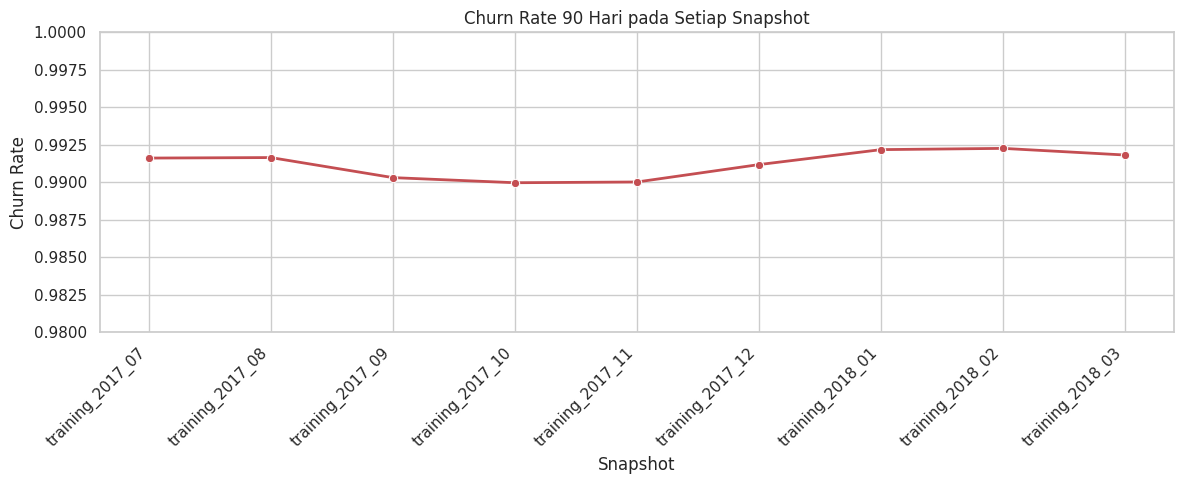

In [ ]:
# Cutoff bulanan untuk data training
training_cutoff_dates = pd.date_range(
    start="2017-07-01",
    end="2018-03-01",
    freq="MS"
)

training_snapshots = []

for cutoff_date in training_cutoff_dates:

    # Enam bulan sebelum cutoff
    feature_start = (
        cutoff_date
        - pd.DateOffset(months=6)
    )

    snapshot_name = (
        "training_"
        + cutoff_date.strftime("%Y_%m")
    )

    snapshot = build_customer_snapshot(
        feature_start=feature_start,
        cutoff_date=cutoff_date,
        snapshot_name=snapshot_name
    )

    training_snapshots.append(
        snapshot
    )

# Menggabungkan seluruh snapshot
calibration = pd.concat(
    training_snapshots,
    ignore_index=True
)

# Holdout terbaru
# Fitur: Desember 2017–Mei 2018
# Label: Juni–Agustus 2018
holdout = build_customer_snapshot(
    feature_start="2017-12-01",
    cutoff_date="2018-06-01",
    snapshot_name="holdout_2018_06"
)

calibration.to_csv(
    DATA_DIR
    / "rolling_training_customer_features.csv",
    index=False
)

holdout.to_csv(
    DATA_DIR
    / "holdout_90_days_customer_features.csv",
    index=False
)

snapshot_summary = (
    calibration
    .groupby("window", as_index=False)
    .agg(
        total_observations=(
            "customer_unique_id",
            "size"
        ),
        unique_customers=(
            "customer_unique_id",
            "nunique"
        ),
        active_customers=(
            "is_churn",
            lambda value:
            (value == 0).sum()
        ),
        churn_customers=(
            "is_churn",
            lambda value:
            (value == 1).sum()
        ),
        churn_rate=(
            "is_churn",
            "mean"
        )
    )
)

display(
    snapshot_summary.round(4)
)

print(
    "Total observasi rolling training:",
    f"{len(calibration):,}"
)

print(
    "Customer unik rolling training:",
    f"{calibration['customer_unique_id'].nunique():,}"
)

print(
    "Jumlah customer holdout:",
    f"{len(holdout):,}"
)

display(
    calibration[
        [
            "customer_unique_id",
            "snapshot_date",
            "label_end_date",
            "recency_days",
            "total_orders",
            "total_spend",
            "is_churn"
        ]
    ].head(10)
)

display(
    holdout[
        [
            "customer_unique_id",
            "snapshot_date",
            "label_end_date",
            "recency_days",
            "total_orders",
            "total_spend",
            "is_churn"
        ]
    ].head(10)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=snapshot_summary,
    x="window",
    y="churn_rate",
    marker="o",
    linewidth=2,
    color="#C44E52"
)

plt.title(
    "Churn Rate 90 Hari pada Setiap Snapshot"
)

plt.xlabel("Snapshot")
plt.ylabel("Churn Rate")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(0.98, 1.00)
plt.tight_layout()
plt.show()

## 11. Analisis distribusi label

,Dataset,Total Observasi,Customer Unik,Active,Churn,Active Rate,Churn Rate
0,Rolling Training,214005,55267,1857,212148,0.0087,0.9913
1,Holdout 90 Hari,38838,38838,260,38578,0.0067,0.9933


,window,is_churn,total_customers,status
0,training_2017_07,0,114,Active
1,training_2017_07,1,13480,Churn
2,training_2017_08,0,139,Active
3,training_2017_08,1,16502,Churn
4,training_2017_09,0,185,Active
5,training_2017_09,1,18906,Churn
6,training_2017_10,0,207,Active
7,training_2017_10,1,20428,Churn
8,training_2017_11,0,227,Active
9,training_2017_11,1,22515,Churn


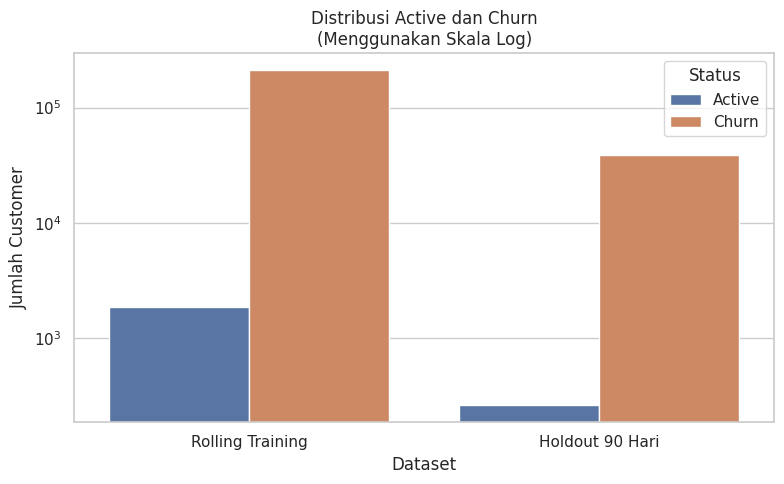

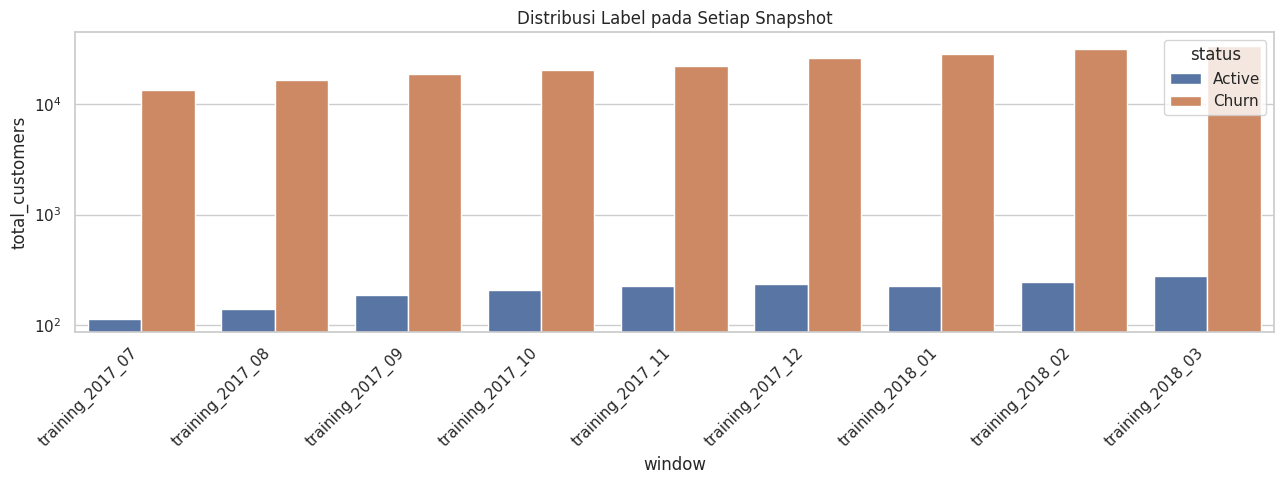

In [ ]:
label_summary = pd.DataFrame([
    {
        "Dataset": "Rolling Training",
        "Total Observasi":
        len(calibration),
        "Customer Unik":
        calibration[
            "customer_unique_id"
        ].nunique(),
        "Active":
        (calibration["is_churn"] == 0).sum(),
        "Churn":
        (calibration["is_churn"] == 1).sum(),
        "Active Rate":
        (calibration["is_churn"] == 0).mean(),
        "Churn Rate":
        calibration["is_churn"].mean()
    },
    {
        "Dataset": "Holdout 90 Hari",
        "Total Observasi":
        len(holdout),
        "Customer Unik":
        holdout[
            "customer_unique_id"
        ].nunique(),
        "Active":
        (holdout["is_churn"] == 0).sum(),
        "Churn":
        (holdout["is_churn"] == 1).sum(),
        "Active Rate":
        (holdout["is_churn"] == 0).mean(),
        "Churn Rate":
        holdout["is_churn"].mean()
    }
])

display(
    label_summary.round(4)
)

# Distribusi setiap snapshot
snapshot_class_distribution = (
    calibration
    .groupby(
        [
            "window",
            "is_churn"
        ],
        as_index=False
    )
    .size()
    .rename(
        columns={
            "size": "total_customers"
        }
    )
)

snapshot_class_distribution[
    "status"
] = snapshot_class_distribution[
    "is_churn"
].map({
    0: "Active",
    1: "Churn"
})

display(
    snapshot_class_distribution.head(20)
)

# Grafik Active dan Churn
label_long = label_summary.melt(
    id_vars="Dataset",
    value_vars=[
        "Active",
        "Churn"
    ],
    var_name="Status",
    value_name="Jumlah Customer"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=label_long,
    x="Dataset",
    y="Jumlah Customer",
    hue="Status"
)

plt.yscale("log")

plt.title(
    "Distribusi Active dan Churn\n"
    "(Menggunakan Skala Log)"
)

plt.tight_layout()
plt.show()

# Grafik per snapshot
plt.figure(figsize=(13, 5))

sns.barplot(
    data=snapshot_class_distribution,
    x="window",
    y="total_customers",
    hue="status"
)

plt.yscale("log")

plt.title(
    "Distribusi Label pada Setiap Snapshot"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

## 12. Preprocessing dan validation split tanpa data leakage

Pada tahap ini data calibration dibagi menjadi development dan validation secara **group-aware**, sehingga customer yang sama tidak berada di kedua subset. Preprocessor belum di-fit di sini; ia akan dimasukkan ke dalam pipeline model agar median, scaling, dan encoding hanya dipelajari dari training fold.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit


numeric_features = [
    "recency_days",
    "total_orders",
    "total_spend",
    "average_order_value",
    "avg_days_between_orders",
    "single_order_flag",
    "avg_review_score",
    "total_reviews",
    "average_items_per_order",
    "total_categories",
    "customer_tenure_days"
]

categorical_features = [
    "favorite_category",
    "payment_method",
    "customer_state"
]

model_features = numeric_features + categorical_features


def make_preprocessor():
    """Membuat preprocessor baru agar dapat di-fit di setiap CV fold."""

    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    try:
        encoder = OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=0.01,
            sparse_output=False
        )
    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=0.01,
            sparse=False
        )

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            encoder
        )
    ])

    return ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ])


X_calibration_raw = calibration[model_features].copy()
X_holdout_raw = holdout[model_features].copy()

y_calibration = calibration["is_churn"].to_numpy()
y_holdout = holdout["is_churn"].to_numpy()

training_groups = calibration["customer_unique_id"].to_numpy()

# Satu validation set yang sama untuk ML dan DL.
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

development_index, validation_index = next(
    group_split.split(
        X_calibration_raw,
        y_calibration,
        groups=training_groups
    )
)

X_development_raw = X_calibration_raw.iloc[development_index].copy()
X_validation_raw = X_calibration_raw.iloc[validation_index].copy()

y_development = y_calibration[development_index]
y_validation = y_calibration[validation_index]

development_groups = training_groups[development_index]
validation_groups = training_groups[validation_index]

assert set(development_groups).isdisjoint(set(validation_groups)), (
    "Customer development dan validation masih tumpang tindih."
)

split_summary = pd.DataFrame([
    {
        "Subset": "Development",
        "Jumlah": len(y_development),
        "Customer Unik": pd.Series(development_groups).nunique(),
        "Active": int((y_development == 0).sum()),
        "Churn": int((y_development == 1).sum()),
        "Churn Rate": y_development.mean()
    },
    {
        "Subset": "Validation",
        "Jumlah": len(y_validation),
        "Customer Unik": pd.Series(validation_groups).nunique(),
        "Active": int((y_validation == 0).sum()),
        "Churn": int((y_validation == 1).sum()),
        "Churn Rate": y_validation.mean()
    },
    {
        "Subset": "Holdout 90 Hari",
        "Jumlah": len(y_holdout),
        "Customer Unik": holdout["customer_unique_id"].nunique(),
        "Active": int((y_holdout == 0).sum()),
        "Churn": int((y_holdout == 1).sum()),
        "Churn Rate": y_holdout.mean()
    }
])

display(split_summary.round(4))

feature_input_table = pd.DataFrame({
    "Tipe": (
        ["Numerik"] * len(numeric_features)
        + ["Kategorikal"] * len(categorical_features)
    ),
    "Fitur Input": model_features
})

display(feature_input_table)

print(
    "Preprocessor belum di-fit dan akan dipelajari di dalam pipeline setiap model."
)

,Subset,Jumlah,Customer Unik,Active,Churn,Churn Rate
0,Development,171164,44213,1475,169689,0.9914
1,Validation,42841,11054,382,42459,0.9911
2,Holdout 90 Hari,38838,38838,260,38578,0.9933


,Tipe,Fitur Input
0,Numerik,recency_days
1,Numerik,total_orders
2,Numerik,total_spend
3,Numerik,average_order_value
4,Numerik,avg_days_between_orders
5,Numerik,single_order_flag
6,Numerik,avg_review_score
7,Numerik,total_reviews
8,Numerik,average_items_per_order
9,Numerik,total_categories


Preprocessor belum di-fit dan akan dipelajari di dalam pipeline setiap model.


## 13. Fungsi evaluasi model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    roc_curve
)


def select_threshold(actual, probability):
    """Memilih threshold dari validation set berdasarkan balanced accuracy."""

    threshold_rows = []

    for threshold in np.linspace(0.05, 0.95, 181):
        prediction = (probability >= threshold).astype(int)

        threshold_rows.append({
            "threshold": threshold,
            "balanced_accuracy": balanced_accuracy_score(
                actual,
                prediction
            ),
            "mcc": matthews_corrcoef(actual, prediction),
            "recall_active": recall_score(
                actual,
                prediction,
                pos_label=0,
                zero_division=0
            )
        })

    threshold_table = (
        pd.DataFrame(threshold_rows)
        .sort_values(
            ["balanced_accuracy", "mcc", "recall_active"],
            ascending=False
        )
        .reset_index(drop=True)
    )

    return float(threshold_table.iloc[0]["threshold"]), threshold_table


def evaluate_model(
    model_name,
    actual,
    probability,
    threshold=0.5
):
    """Menghitung evaluasi lengkap pada probabilitas dan threshold tertentu."""

    prediction = (probability >= threshold).astype(int)

    metrics = {
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(actual, prediction),
        "balanced_accuracy": balanced_accuracy_score(actual, prediction),
        "precision_churn": precision_score(
            actual, prediction, pos_label=1, zero_division=0
        ),
        "recall_churn": recall_score(
            actual, prediction, pos_label=1, zero_division=0
        ),
        "f1_churn": f1_score(
            actual, prediction, pos_label=1, zero_division=0
        ),
        "precision_active": precision_score(
            actual, prediction, pos_label=0, zero_division=0
        ),
        "recall_active": recall_score(
            actual, prediction, pos_label=0, zero_division=0
        ),
        "f1_active": f1_score(
            actual, prediction, pos_label=0, zero_division=0
        ),
        "roc_auc": roc_auc_score(actual, probability),
        "pr_auc_churn": average_precision_score(actual, probability),
        "pr_auc_active": average_precision_score(
            1 - actual,
            1 - probability
        ),
        "mcc": matthews_corrcoef(actual, prediction)
    }

    report = classification_report(
        actual,
        prediction,
        labels=[0, 1],
        target_names=["Active", "Churn"],
        output_dict=True,
        zero_division=0
    )

    matrix = confusion_matrix(
        actual,
        prediction,
        labels=[0, 1]
    )

    return metrics, prediction, report, matrix


metric_information = pd.DataFrame({
    "Metrik": [
        "Balanced Accuracy",
        "PR-AUC Active",
        "Recall Active",
        "F1 Active",
        "ROC-AUC",
        "MCC",
        "Accuracy"
    ],
    "Kegunaan": [
        "Kinerja rata-rata pada kelas Active dan Churn",
        "Kemampuan ranking untuk kelas Active yang sangat sedikit",
        "Persentase customer Active yang berhasil ditemukan",
        "Gabungan precision dan recall kelas Active",
        "Kemampuan membedakan kedua kelas tanpa threshold tertentu",
        "Korelasi prediksi dan aktual pada data tidak seimbang",
        "Metrik pendukung karena kelas sangat tidak seimbang"
    ],
    "Penggunaan": [
        "Pemilihan threshold",
        "Pemilihan model",
        "Evaluasi utama",
        "Evaluasi utama",
        "Evaluasi utama",
        "Evaluasi utama",
        "Pendukung"
    ]
})

display(metric_information)

,Metrik,Kegunaan,Penggunaan
0,Balanced Accuracy,Kinerja rata-rata pada kelas Active dan Churn,Pemilihan threshold
1,PR-AUC Active,Kemampuan ranking untuk kelas Active yang sang...,Pemilihan model
2,Recall Active,Persentase customer Active yang berhasil ditem...,Evaluasi utama
3,F1 Active,Gabungan precision dan recall kelas Active,Evaluasi utama
4,ROC-AUC,Kemampuan membedakan kedua kelas tanpa thresho...,Evaluasi utama
5,MCC,Korelasi prediksi dan aktual pada data tidak s...,Evaluasi utama
6,Accuracy,Metrik pendukung karena kelas sangat tidak sei...,Pendukung


## 14. Training tiga model Machine Learning

Hyperparameter dicari hanya pada development set menggunakan `StratifiedGroupKFold`. Threshold setiap model ditentukan dari validation set, model kemudian di-fit ulang pada seluruh calibration, dan holdout digunakan sekali sebagai evaluasi akhir.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV


try:
    from sklearn.model_selection import StratifiedGroupKFold

    cross_validation = StratifiedGroupKFold(
        n_splits=3,
        shuffle=True,
        random_state=SEED
    )
    cv_method = "StratifiedGroupKFold"

except ImportError:
    from sklearn.model_selection import GroupKFold

    cross_validation = GroupKFold(n_splits=3)
    cv_method = "GroupKFold"

print("Metode cross-validation:", cv_method)


def model_pipeline(classifier):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", classifier)
    ])


model_searches = {
    "Logistic Regression": RandomizedSearchCV(
        estimator=model_pipeline(
            LogisticRegression(random_state=SEED)
        ),
        param_distributions={
            "classifier__C": np.logspace(-3, 2, 20),
            "classifier__class_weight": ["balanced"],
            "classifier__solver": ["lbfgs"],
            "classifier__max_iter": [2000]
        },
        n_iter=N_ITER_ML,
        scoring="roc_auc",
        cv=cross_validation,
        random_state=SEED,
        n_jobs=-1,
        refit=True
    ),
    "Random Forest": RandomizedSearchCV(
        estimator=model_pipeline(
            RandomForestClassifier(
                random_state=SEED,
                n_jobs=-1
            )
        ),
        param_distributions={
            "classifier__n_estimators": [150, 250, 350],
            "classifier__max_depth": [4, 6, 8, 10],
            "classifier__min_samples_leaf": [2, 5, 10, 20],
            "classifier__max_features": ["sqrt", "log2"],
            "classifier__class_weight": ["balanced"]
        },
        n_iter=N_ITER_ML,
        scoring="roc_auc",
        cv=cross_validation,
        random_state=SEED,
        n_jobs=-1,
        refit=True
    ),
    "Histogram Gradient Boosting": RandomizedSearchCV(
        estimator=model_pipeline(
            HistGradientBoostingClassifier(
                random_state=SEED,
                class_weight="balanced"
            )
        ),
        param_distributions={
            "classifier__learning_rate": [0.03, 0.05, 0.10],
            "classifier__max_iter": [100, 150, 200],
            "classifier__max_leaf_nodes": [15, 31, 63],
            "classifier__min_samples_leaf": [10, 20, 30],
            "classifier__l2_regularization": [0.0, 0.1, 1.0]
        },
        n_iter=N_ITER_ML,
        scoring="roc_auc",
        cv=cross_validation,
        random_state=SEED,
        n_jobs=-1,
        refit=True
    )
}

display(pd.DataFrame([
    {
        "Model": model_name,
        "Random Search Trials": N_ITER_ML,
        "CV Folds": 3,
        "Preprocessing dalam CV": "Ya"
    }
    for model_name in model_searches
]))

trained_models = {}
model_probabilities = {}
validation_probabilities = {}
model_predictions = {}
model_thresholds = {}

metrics_rows = []
validation_metrics_rows = []
classification_reports = {}
confusion_matrices = {}
roc_results = {}
best_parameters = {}

for model_name, search in model_searches.items():
    print("\n" + "=" * 65)
    print("TUNING:", model_name)
    print("=" * 65)

    search.fit(
        X_development_raw,
        y_development,
        groups=development_groups
    )

    tuned_model = search.best_estimator_

    validation_probability = tuned_model.predict_proba(
        X_validation_raw
    )[:, 1]

    threshold, threshold_table = select_threshold(
        y_validation,
        validation_probability
    )

    validation_metrics, _, _, _ = evaluate_model(
        model_name,
        y_validation,
        validation_probability,
        threshold
    )
    validation_metrics["cv_roc_auc"] = search.best_score_
    validation_metrics_rows.append(validation_metrics)

    # Fit ulang konfigurasi terpilih pada seluruh calibration.
    final_model = search.best_estimator_
    final_model.fit(X_calibration_raw, y_calibration)

    holdout_probability = final_model.predict_proba(
        X_holdout_raw
    )[:, 1]

    holdout_metrics, prediction, report, matrix = evaluate_model(
        model_name,
        y_holdout,
        holdout_probability,
        threshold
    )
    holdout_metrics["cv_roc_auc"] = search.best_score_
    holdout_metrics["selection_roc_auc"] = validation_metrics["roc_auc"]
    metrics_rows.append(holdout_metrics)

    trained_models[model_name] = final_model
    model_probabilities[model_name] = holdout_probability
    validation_probabilities[model_name] = validation_probability
    model_predictions[model_name] = prediction
    model_thresholds[model_name] = threshold
    classification_reports[model_name] = report
    confusion_matrices[model_name] = matrix
    best_parameters[model_name] = search.best_params_

    fpr, tpr, _ = roc_curve(y_holdout, holdout_probability)
    roc_results[model_name] = (fpr, tpr, holdout_metrics["roc_auc"])

    print("Best parameters:", search.best_params_)
    print("CV ROC-AUC:", round(search.best_score_, 4))
    print("Validation threshold:", round(threshold, 4))
    print("Validation PR-AUC Active:", round(validation_metrics["pr_auc_active"], 4))
    print("Holdout ROC-AUC:", round(holdout_metrics["roc_auc"], 4))

validation_ml_metrics = pd.DataFrame(validation_metrics_rows)
holdout_ml_metrics = pd.DataFrame(metrics_rows)

display(validation_ml_metrics.round(4))
display(holdout_ml_metrics.round(4))

best_parameter_table = pd.DataFrame([
    {
        "Model": model_name,
        "Best Parameters": str(parameters),
        "Validation Threshold": model_thresholds[model_name]
    }
    for model_name, parameters in best_parameters.items()
])

display(best_parameter_table)

joblib.dump(
    trained_models,
    MODEL_DIR / "machine_learning_models.joblib"
)

holdout_ml_metrics.to_csv(
    OUTPUT_DIR / "machine_learning_metrics.csv",
    index=False
)

Metode cross-validation: StratifiedGroupKFold


,Model,Random Search Trials,CV Folds,Preprocessing dalam CV
0,Logistic Regression,5,3,Ya
1,Random Forest,5,3,Ya
2,Histogram Gradient Boosting,5,3,Ya



TUNING: Logistic Regression
Best parameters: {'classifier__solver': 'lbfgs', 'classifier__max_iter': 2000, 'classifier__class_weight': 'balanced', 'classifier__C': np.float64(8.858667904100823)}
CV ROC-AUC: 0.605
Validation threshold: 0.42
Validation PR-AUC Active: 0.0244
Holdout ROC-AUC: 0.6097

TUNING: Random Forest
Best parameters: {'classifier__n_estimators': 150, 'classifier__min_samples_leaf': 20, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 6, 'classifier__class_weight': 'balanced'}
CV ROC-AUC: 0.5838
Validation threshold: 0.51
Validation PR-AUC Active: 0.0184
Holdout ROC-AUC: 0.6149

TUNING: Histogram Gradient Boosting
Best parameters: {'classifier__min_samples_leaf': 10, 'classifier__max_leaf_nodes': 63, 'classifier__max_iter': 100, 'classifier__learning_rate': 0.03, 'classifier__l2_regularization': 0.0}
CV ROC-AUC: 0.5821
Validation threshold: 0.445
Validation PR-AUC Active: 0.0188
Holdout ROC-AUC: 0.5626


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc
0,Logistic Regression,0.420,0.8510,0.5720,0.9926,0.8561,0.9193,0.0177,0.2880,0.0333,0.5859,0.9926,0.0244,0.0384,0.6050
1,Random Forest,0.510,0.7620,0.5712,0.9927,0.7654,0.8644,0.0143,0.3770,0.0275,0.5728,0.9924,0.0184,0.0315,0.5838
2,Histogram Gradient Boosting,0.445,0.8993,0.5458,0.9920,0.9057,0.9469,0.0174,0.1859,0.0319,0.5466,0.9918,0.0188,0.0293,0.5821


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,selection_roc_auc
0,Logistic Regression,0.420,0.8933,0.5891,0.9946,0.8974,0.9435,0.0181,0.2808,0.0340,0.6097,0.9950,0.0196,0.0476,0.6050,0.5859
1,Random Forest,0.510,0.8089,0.6001,0.9949,0.8118,0.8941,0.0137,0.3885,0.0265,0.6149,0.9950,0.0202,0.0417,0.5838,0.5728
2,Histogram Gradient Boosting,0.445,0.9039,0.5562,0.9941,0.9086,0.9494,0.0148,0.2038,0.0276,0.5626,0.9942,0.0197,0.0317,0.5821,0.5466


,Model,Best Parameters,Validation Threshold
0,Logistic Regression,"{'classifier__solver': 'lbfgs', 'classifier__m...",0.420
1,Random Forest,"{'classifier__n_estimators': 150, 'classifier_...",0.510
2,Histogram Gradient Boosting,"{'classifier__min_samples_leaf': 10, 'classifi...",0.445


## 15. Deep Learning Keras MLP

Konfigurasi neural network dipilih berdasarkan validation set yang sama dengan model machine learning. Preprocessor deep learning juga dipelajari hanya dari development ketika tuning dan di-fit ulang pada seluruh calibration sebelum pengujian holdout.

,Class,Weight
0,Active (0),58.0217
1,Churn (1),0.5043


,Hyperparameter,Pilihan
0,number_layers,"[1, 2, 3]"
1,units,"[32, 64, 128]"
2,dropout,"[0.0, 0.2, 0.3]"
3,learning_rate,"[0.01, 0.005, 0.001]"
4,batch_size,"[128, 256, 512]"


Trial 1/4 | Validation AUC = 0.5795
Trial 2/4 | Validation AUC = 0.5826
Trial 3/4 | Validation AUC = 0.5783
Trial 4/4 | Validation AUC = 0.5857


,number_layers,units,dropout,learning_rate,batch_size,best_epoch,validation_auc
0,3,32,0.3,0.001,512,5,0.5857
1,1,128,0.3,0.001,128,6,0.5826
2,3,32,0.0,0.001,256,2,0.5795
3,1,32,0.0,0.010,512,5,0.5783


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc
0,Deep Learning (Keras MLP),0.495,0.863,0.5638,0.9924,0.8685,0.9263,0.0174,0.2592,0.0326,0.5836,0.993,0.0238,0.0354,NaN


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,selection_roc_auc
0,Deep Learning (Keras MLP),0.495,0.719,0.5854,0.9949,0.7208,0.8359,0.0107,0.45,0.021,0.6196,0.9952,0.0176,0.031,NaN,0.5836


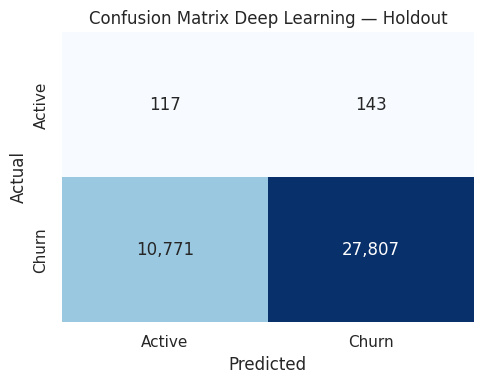

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


tf.random.set_seed(SEED)

# Preprocessing tuning dipelajari hanya dari development.
dl_tuning_preprocessor = make_preprocessor()

X_train_dl = dl_tuning_preprocessor.fit_transform(
    X_development_raw
).astype("float32")

X_validation_dl = dl_tuning_preprocessor.transform(
    X_validation_raw
).astype("float32")


def create_class_weight(target):
    total_active = max(int((target == 0).sum()), 1)
    total_churn = max(int((target == 1).sum()), 1)

    return {
        0: len(target) / (2 * total_active),
        1: len(target) / (2 * total_churn)
    }


class_weight_dl = create_class_weight(y_development)

display(pd.DataFrame({
    "Class": ["Active (0)", "Churn (1)"],
    "Weight": [class_weight_dl[0], class_weight_dl[1]]
}).round(4))


def build_dl_model(
    input_dim,
    number_layers,
    units,
    dropout,
    learning_rate
):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,))
    ])

    for layer_number in range(number_layers):
        current_units = max(units // (2 ** layer_number), 8)
        model.add(layers.Dense(current_units, activation="relu"))

        if dropout > 0:
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")]
    )

    return model


search_space_dl = {
    "number_layers": [1, 2, 3],
    "units": [32, 64, 128],
    "dropout": [0.0, 0.2, 0.3],
    "learning_rate": [0.01, 0.005, 0.001],
    "batch_size": [128, 256, 512]
}

display(pd.DataFrame({
    "Hyperparameter": list(search_space_dl.keys()),
    "Pilihan": [str(value) for value in search_space_dl.values()]
}))

trial_results = []
best_validation_auc = -np.inf
best_configuration = None
best_epoch = 1
best_validation_probability = None

for trial_number in range(N_TRIALS_DL):
    configuration = {
        key: random.choice(values)
        for key, values in search_space_dl.items()
    }

    model = build_dl_model(
        input_dim=X_train_dl.shape[1],
        number_layers=configuration["number_layers"],
        units=configuration["units"],
        dropout=configuration["dropout"],
        learning_rate=configuration["learning_rate"]
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=4,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_dl,
        y_development,
        validation_data=(X_validation_dl, y_validation),
        epochs=MAX_EPOCHS,
        batch_size=configuration["batch_size"],
        class_weight=class_weight_dl,
        callbacks=[early_stopping],
        verbose=0
    )

    validation_auc_values = history.history["val_auc"]
    current_best_epoch = int(np.argmax(validation_auc_values) + 1)
    current_best_auc = float(np.max(validation_auc_values))

    trial_results.append({
        **configuration,
        "best_epoch": current_best_epoch,
        "validation_auc": current_best_auc
    })

    print(
        f"Trial {trial_number + 1}/{N_TRIALS_DL} | "
        f"Validation AUC = {current_best_auc:.4f}"
    )

    if current_best_auc > best_validation_auc:
        best_validation_auc = current_best_auc
        best_configuration = configuration.copy()
        best_epoch = current_best_epoch
        best_validation_probability = model.predict(
            X_validation_dl,
            verbose=0
        ).ravel()

trial_dataframe = (
    pd.DataFrame(trial_results)
    .sort_values("validation_auc", ascending=False)
    .reset_index(drop=True)
)

display(trial_dataframe.round(4))

dl_threshold, dl_threshold_table = select_threshold(
    y_validation,
    best_validation_probability
)

dl_model_name = "Deep Learning (Keras MLP)"

dl_validation_metrics, _, _, _ = evaluate_model(
    dl_model_name,
    y_validation,
    best_validation_probability,
    dl_threshold
)
dl_validation_metrics["cv_roc_auc"] = np.nan
validation_metrics_rows.append(dl_validation_metrics)

# Fit ulang preprocessor dan model pada seluruh calibration.
final_dl_preprocessor = make_preprocessor()

X_calibration_dl = final_dl_preprocessor.fit_transform(
    X_calibration_raw
).astype("float32")

X_holdout_dl = final_dl_preprocessor.transform(
    X_holdout_raw
).astype("float32")

final_dl_model = build_dl_model(
    input_dim=X_calibration_dl.shape[1],
    number_layers=best_configuration["number_layers"],
    units=best_configuration["units"],
    dropout=best_configuration["dropout"],
    learning_rate=best_configuration["learning_rate"]
)

final_dl_model.fit(
    X_calibration_dl,
    y_calibration,
    epochs=best_epoch,
    batch_size=best_configuration["batch_size"],
    class_weight=create_class_weight(y_calibration),
    verbose=0
)

dl_probability = final_dl_model.predict(
    X_holdout_dl,
    verbose=0
).ravel()

dl_metrics, dl_prediction, dl_report, dl_matrix = evaluate_model(
    dl_model_name,
    y_holdout,
    dl_probability,
    dl_threshold
)
dl_metrics["cv_roc_auc"] = np.nan
dl_metrics["selection_roc_auc"] = dl_validation_metrics["roc_auc"]
metrics_rows.append(dl_metrics)

model_probabilities[dl_model_name] = dl_probability
validation_probabilities[dl_model_name] = best_validation_probability
model_predictions[dl_model_name] = dl_prediction
model_thresholds[dl_model_name] = dl_threshold
classification_reports[dl_model_name] = dl_report
confusion_matrices[dl_model_name] = dl_matrix

dl_fpr, dl_tpr, _ = roc_curve(y_holdout, dl_probability)
roc_results[dl_model_name] = (
    dl_fpr,
    dl_tpr,
    dl_metrics["roc_auc"]
)

final_dl_model.save(MODEL_DIR / "deep_learning_model.keras")
joblib.dump(
    final_dl_preprocessor,
    MODEL_DIR / "deep_learning_preprocessor.joblib"
)

pd.DataFrame(trial_results).to_csv(
    OUTPUT_DIR / "deep_learning_trials.csv",
    index=False
)

display(pd.DataFrame([dl_validation_metrics]).round(4))
display(pd.DataFrame([dl_metrics]).round(4))

plt.figure(figsize=(5, 4))
sns.heatmap(
    dl_matrix,
    annot=True,
    fmt=",",
    cmap="Blues",
    cbar=False,
    xticklabels=["Active", "Churn"],
    yticklabels=["Active", "Churn"]
)
plt.title("Confusion Matrix Deep Learning — Holdout")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## 16. Perbandingan dan pemilihan model terbaik

Model terbaik dipilih dari **PR-AUC kelas Active pada validation set**, bukan dari holdout. Hal ini penting karena Active merupakan kelas minoritas dan holdout harus tetap menjadi data pengujian akhir.

Hasil validation untuk pemilihan model:


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc
0,Logistic Regression,0.420,0.8510,0.5720,0.9926,0.8561,0.9193,0.0177,0.2880,0.0333,0.5859,0.9926,0.0244,0.0384,0.6050
1,Deep Learning (Keras MLP),0.495,0.8630,0.5638,0.9924,0.8685,0.9263,0.0174,0.2592,0.0326,0.5836,0.9930,0.0238,0.0354,NaN
2,Histogram Gradient Boosting,0.445,0.8993,0.5458,0.9920,0.9057,0.9469,0.0174,0.1859,0.0319,0.5466,0.9918,0.0188,0.0293,0.5821
3,Random Forest,0.510,0.7620,0.5712,0.9927,0.7654,0.8644,0.0143,0.3770,0.0275,0.5728,0.9924,0.0184,0.0315,0.5838


Hasil holdout untuk pelaporan final:


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,selection_roc_auc
0,Deep Learning (Keras MLP),0.495,0.7190,0.5854,0.9949,0.7208,0.8359,0.0107,0.4500,0.0210,0.6196,0.9952,0.0176,0.0310,NaN,0.5836
1,Histogram Gradient Boosting,0.445,0.9039,0.5562,0.9941,0.9086,0.9494,0.0148,0.2038,0.0276,0.5626,0.9942,0.0197,0.0317,0.5821,0.5466
2,Logistic Regression,0.420,0.8933,0.5891,0.9946,0.8974,0.9435,0.0181,0.2808,0.0340,0.6097,0.9950,0.0196,0.0476,0.6050,0.5859
3,Random Forest,0.510,0.8089,0.6001,0.9949,0.8118,0.8941,0.0137,0.3885,0.0265,0.6149,0.9950,0.0202,0.0417,0.5838,0.5728


Model terpilih berdasarkan PR-AUC Active validation:
Logistic Regression


,model,threshold,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,precision_active,recall_active,f1_active,roc_auc,pr_auc_churn,pr_auc_active,mcc,cv_roc_auc,selection_roc_auc
2,Logistic Regression,0.42,0.8933,0.5891,0.9946,0.8974,0.9435,0.0181,0.2808,0.034,0.6097,0.995,0.0196,0.0476,0.605,0.5859


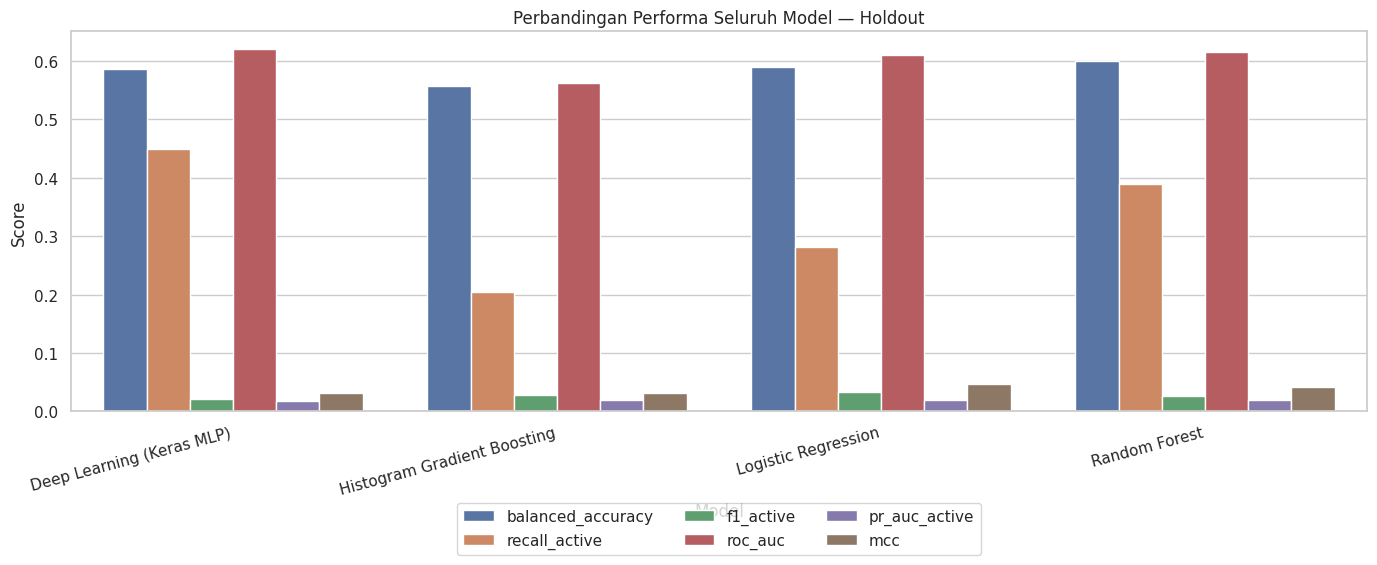

In [ ]:
# Tabel validation digunakan untuk pemilihan model.
validation_metrics_dataframe = (
    pd.DataFrame(validation_metrics_rows)
    .sort_values(
        ["pr_auc_active", "roc_auc", "mcc"],
        ascending=False
    )
    .reset_index(drop=True)
)

# Tabel holdout hanya digunakan untuk evaluasi final.
metrics_dataframe = (
    pd.DataFrame(metrics_rows)
    .sort_values("model")
    .reset_index(drop=True)
)

best_model_name = validation_metrics_dataframe.iloc[0]["model"]

best_model_result = metrics_dataframe[
    metrics_dataframe["model"] == best_model_name
].copy()

validation_metrics_dataframe.to_csv(
    OUTPUT_DIR / "model_selection_validation.csv",
    index=False
)

metrics_dataframe.to_csv(
    OUTPUT_DIR / "model_performance_comparison.csv",
    index=False
)

comparison_all_sets = pd.concat([
    validation_metrics_dataframe.assign(evaluation_set="Validation"),
    metrics_dataframe.assign(evaluation_set="Holdout")
], ignore_index=True)

comparison_all_sets.to_csv(
    OUTPUT_DIR / "model_validation_and_holdout.csv",
    index=False
)

print("Hasil validation untuk pemilihan model:")
display(validation_metrics_dataframe.round(4))

print("Hasil holdout untuk pelaporan final:")
display(metrics_dataframe.round(4))

print("Model terpilih berdasarkan PR-AUC Active validation:")
print(best_model_name)
display(best_model_result.round(4))

if best_model_name in trained_models:
    selected_preprocessor = trained_models[
        best_model_name
    ].named_steps["preprocessor"]
else:
    selected_preprocessor = final_dl_preprocessor

selected_feature_names = selected_preprocessor.get_feature_names_out()
selected_feature_count = len(selected_feature_names)

metrics_long = metrics_dataframe.melt(
    id_vars="model",
    value_vars=[
        "balanced_accuracy",
        "recall_active",
        "f1_active",
        "roc_auc",
        "pr_auc_active",
        "mcc"
    ],
    var_name="metric",
    value_name="score"
)

plt.figure(figsize=(14, 6))
sns.barplot(
    data=metrics_long,
    x="model",
    y="score",
    hue="metric"
)
plt.title("Perbandingan Performa Seluruh Model — Holdout")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3
)
plt.tight_layout()
plt.show()

## 17. Confusion matrix, ROC Curve, dan feature importance

,Model,Class,Precision,Recall,F1 Score,Support
0,Logistic Regression,Active,0.0181,0.2808,0.0340,260.0
1,Logistic Regression,Churn,0.9946,0.8974,0.9435,38578.0
2,Random Forest,Active,0.0137,0.3885,0.0265,260.0
3,Random Forest,Churn,0.9949,0.8118,0.8941,38578.0
4,Histogram Gradient Boosting,Active,0.0148,0.2038,0.0276,260.0
5,Histogram Gradient Boosting,Churn,0.9941,0.9086,0.9494,38578.0
6,Deep Learning (Keras MLP),Active,0.0107,0.4500,0.0210,260.0
7,Deep Learning (Keras MLP),Churn,0.9949,0.7208,0.8359,38578.0


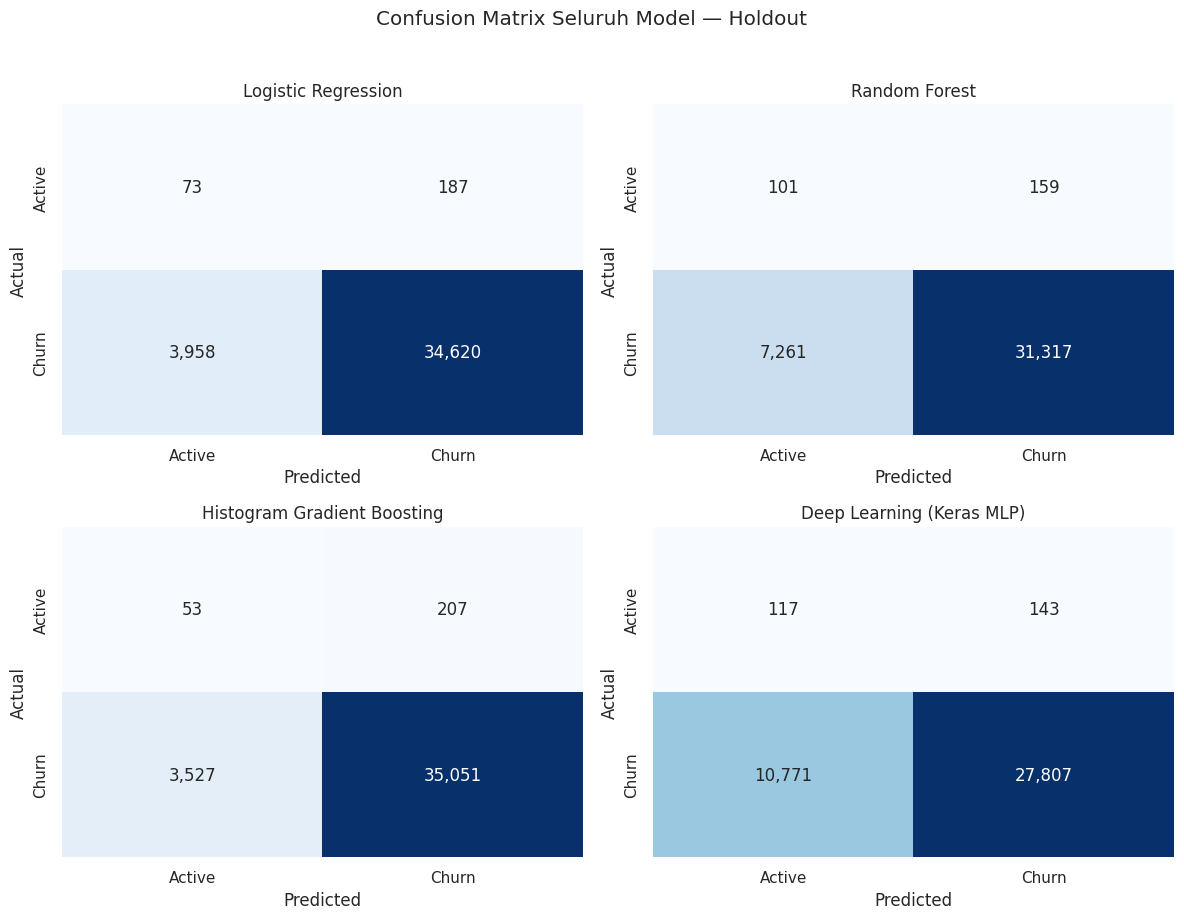

,Model,Actual Active - Predicted Active,Actual Active - Predicted Churn,Actual Churn - Predicted Active,Actual Churn - Predicted Churn
0,Logistic Regression,73,187,3958,34620
1,Random Forest,101,159,7261,31317
2,Histogram Gradient Boosting,53,207,3527,35051
3,Deep Learning (Keras MLP),117,143,10771,27807


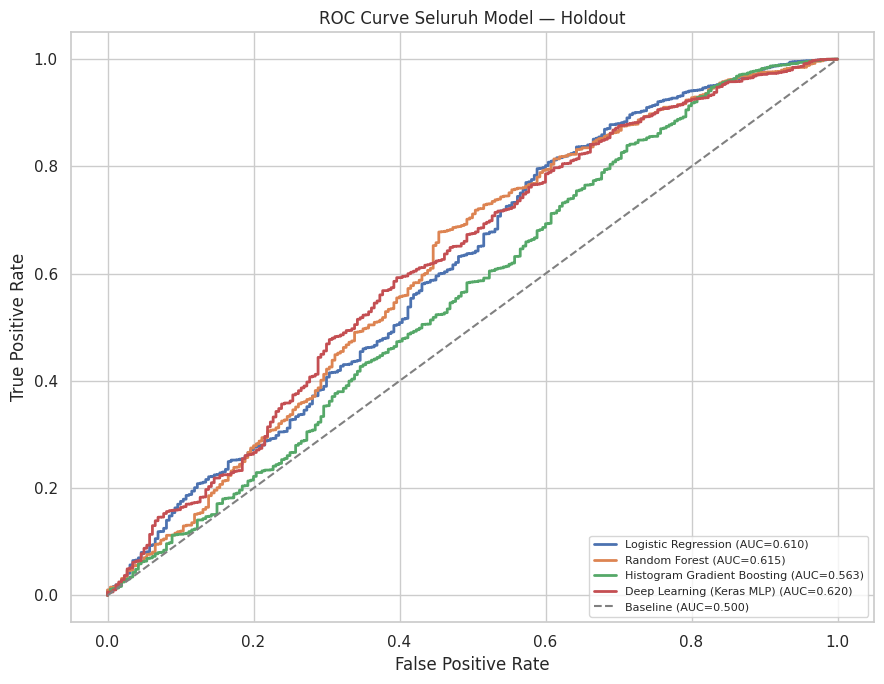

,model,threshold,roc_auc,balanced_accuracy,recall_active,mcc
0,Deep Learning (Keras MLP),0.495,0.6196,0.5854,0.4500,0.0310
3,Random Forest,0.510,0.6149,0.6001,0.3885,0.0417
2,Logistic Regression,0.420,0.6097,0.5891,0.2808,0.0476
1,Histogram Gradient Boosting,0.445,0.5626,0.5562,0.2038,0.0317


,feature,importance
1,numeric__total_orders,0.1088
10,numeric__customer_tenure_days,0.1013
4,numeric__avg_days_between_orders,0.1010
0,numeric__recency_days,0.0976
7,numeric__total_reviews,0.0898
5,numeric__single_order_flag,0.0737
3,numeric__average_order_value,0.0712
2,numeric__total_spend,0.0656
8,numeric__average_items_per_order,0.0331
6,numeric__avg_review_score,0.0328


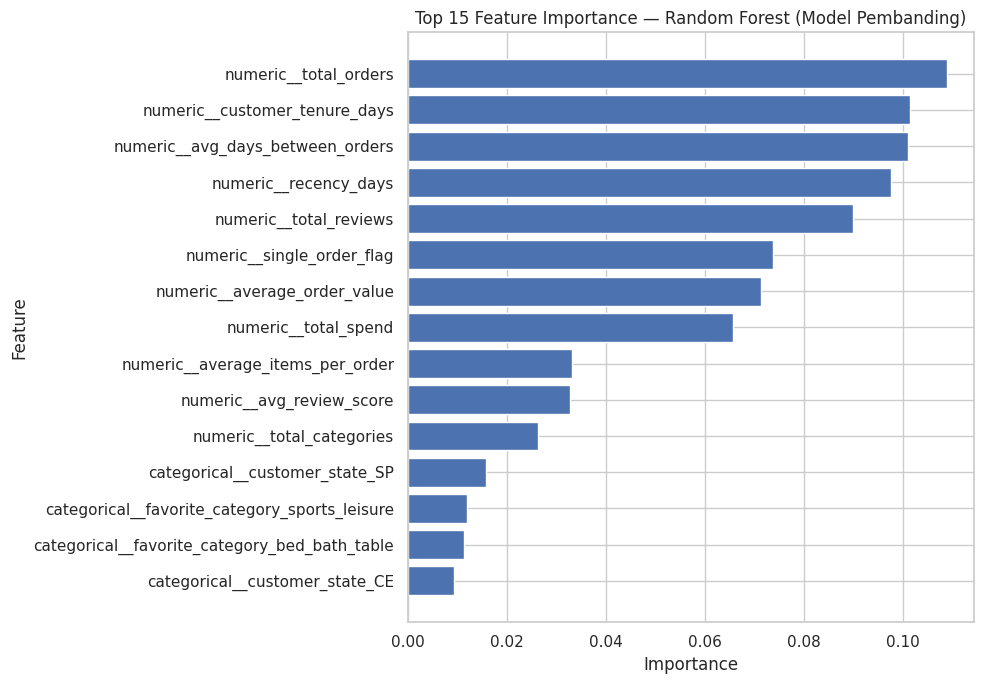

Catatan: feature importance berikut berasal dari Random Forest sebagai model pembanding. Model utama tetap dipilih berdasarkan PR-AUC kelas Active pada validation set.


In [ ]:
# ============================================================
# 1. CLASSIFICATION REPORT HOLDOUT
# ============================================================

classification_report_rows = []

for model_name, report in classification_reports.items():
    for class_name in ["Active", "Churn"]:
        classification_report_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1 Score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

classification_report_dataframe = pd.DataFrame(
    classification_report_rows
)

classification_report_dataframe.to_csv(
    OUTPUT_DIR / "classification_reports.csv",
    index=False
)

display(classification_report_dataframe.round(4))

# ============================================================
# 2. CONFUSION MATRIX SELURUH MODEL
# ============================================================

number_models = len(confusion_matrices)
figure, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()
confusion_matrix_rows = []

for axis, (model_name, matrix) in zip(
    axes,
    confusion_matrices.items()
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=",",
        cmap="Blues",
        cbar=False,
        ax=axis,
        xticklabels=["Active", "Churn"],
        yticklabels=["Active", "Churn"]
    )
    axis.set_title(model_name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")

    confusion_matrix_rows.append({
        "Model": model_name,
        "Actual Active - Predicted Active": matrix[0, 0],
        "Actual Active - Predicted Churn": matrix[0, 1],
        "Actual Churn - Predicted Active": matrix[1, 0],
        "Actual Churn - Predicted Churn": matrix[1, 1]
    })

for empty_axis in axes[number_models:]:
    empty_axis.axis("off")

plt.suptitle("Confusion Matrix Seluruh Model — Holdout", y=1.02)
plt.tight_layout()
plt.savefig(
    FIG_DIR / "confusion_matrix_all_models.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

confusion_matrix_dataframe = pd.DataFrame(confusion_matrix_rows)
confusion_matrix_dataframe.to_csv(
    OUTPUT_DIR / "confusion_matrices.csv",
    index=False
)
display(confusion_matrix_dataframe)

# ============================================================
# 3. ROC CURVE HOLDOUT
# ============================================================

plt.figure(figsize=(9, 7))

for model_name, (false_positive_rate, true_positive_rate, auc_value) in roc_results.items():
    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"{model_name} (AUC={auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Baseline (AUC=0.500)"
)
plt.title("ROC Curve Seluruh Model — Holdout")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(
    FIG_DIR / "roc_curve_all_models.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

display(
    metrics_dataframe[
        ["model", "threshold", "roc_auc", "balanced_accuracy", "recall_active", "mcc"]
    ].sort_values("roc_auc", ascending=False).round(4)
)

# ============================================================
# 4. FEATURE IMPORTANCE RANDOM FOREST
# ============================================================

random_forest_pipeline = trained_models["Random Forest"]
random_forest_preprocessor = random_forest_pipeline.named_steps["preprocessor"]
random_forest_classifier = random_forest_pipeline.named_steps["classifier"]

feature_names = random_forest_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": random_forest_classifier.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

top_15_features = feature_importance.head(15)
display(top_15_features.round(4))

plt.figure(figsize=(10, 7))
plot_importance = top_15_features.sort_values("importance")
plt.barh(
    plot_importance["feature"],
    plot_importance["importance"],
    color="#4C72B0"
)
plt.title(
    "Top 15 Feature Importance — Random Forest (Model Pembanding)"
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(
    FIG_DIR / "feature_importance_top15.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
print(
    "Catatan: feature importance berikut berasal dari Random Forest "
    "sebagai model pembanding. Model utama tetap dipilih berdasarkan "
    "PR-AUC kelas Active pada validation set."
)

## 18. Explainable AI menggunakan SHAP

SHAP digunakan untuk menjelaskan model yang dipilih dari validation set.
Penjelasan terdiri dari:

- **Global explanation:** fitur yang paling berpengaruh terhadap seluruh
  prediksi.
- **Local explanation:** alasan satu customer memperoleh probabilitas churn
  tertentu.
- **Grouped business features:** hasil one-hot encoding digabungkan kembali
  menjadi fitur bisnis seperti kategori favorit, metode pembayaran, dan state.

Nilai SHAP positif mendorong prediksi menuju kelas **Churn (1)**, sedangkan
nilai SHAP negatif menahan prediksi churn atau mendorongnya menuju kelas
**Active (0)**. SHAP menjelaskan perilaku model dan tidak membuktikan hubungan
sebab-akibat.


SHAP version: 0.52.0

Model yang akan dijelaskan:
Logistic Regression

Jenis classifier:
LogisticRegression

Contoh nama fitur hasil preprocessing:


,Original Feature,Readable Feature,Business Group
0,numeric__recency_days,Recency (days),Recency
1,numeric__total_orders,Total Orders,Total Orders
2,numeric__total_spend,Total Spend,Total Spend
3,numeric__average_order_value,Average Order Value,Average Order Value
4,numeric__avg_days_between_orders,Average Days Between Orders,Average Days Between Orders
5,numeric__single_order_flag,Single Order Customer,Single Order Customer
6,numeric__avg_review_score,Average Review Score,Average Review Score
7,numeric__total_reviews,Total Reviews,Total Reviews
8,numeric__average_items_per_order,Average Items per Order,Average Items per Order
9,numeric__total_categories,Total Categories,Total Categories



Jumlah background SHAP: 500
Jumlah customer holdout: 38838
Jumlah fitur: 52

Model yang dijelaskan: Logistic Regression
Jenis SHAP explainer: LinearExplainer
Jumlah customer yang dijelaskan: 38,838
Jumlah fitur setelah preprocessing: 52

15 fitur SHAP terpenting:


,feature,original_transformed_feature,business_group,mean_abs_shap,mean_signed_shap,average_direction
0,Recency (days),numeric__recency_days,Recency,0.538901,0.122271,Secara neto mendorong prediksi Churn
1,Customer Tenure (days),numeric__customer_tenure_days,Customer Tenure,0.427726,-0.112577,Secara neto menahan prediksi Churn
2,Customer State = Sp,categorical__customer_state_SP,Customer State,0.119088,-0.003434,Secara neto menahan prediksi Churn
3,Average Review Score,numeric__avg_review_score,Average Review Score,0.106878,0.009675,Secara neto mendorong prediksi Churn
4,Total Orders,numeric__total_orders,Total Orders,0.090265,0.014508,Secara neto mendorong prediksi Churn
5,Favorite Category = Bed Bath Table,categorical__favorite_category_bed_bath_table,Favorite Category,0.058503,0.012926,Secara neto mendorong prediksi Churn
6,Favorite Category = Sports Leisure,categorical__favorite_category_sports_leisure,Favorite Category,0.056245,0.000257,Secara neto mendorong prediksi Churn
7,Average Items per Order,numeric__average_items_per_order,Average Items per Order,0.053086,-0.003016,Secara neto menahan prediksi Churn
8,Customer State = Rj,categorical__customer_state_RJ,Customer State,0.048765,0.004434,Secara neto mendorong prediksi Churn
9,Total Spend,numeric__total_spend,Total Spend,0.044763,-0.003349,Secara neto menahan prediksi Churn


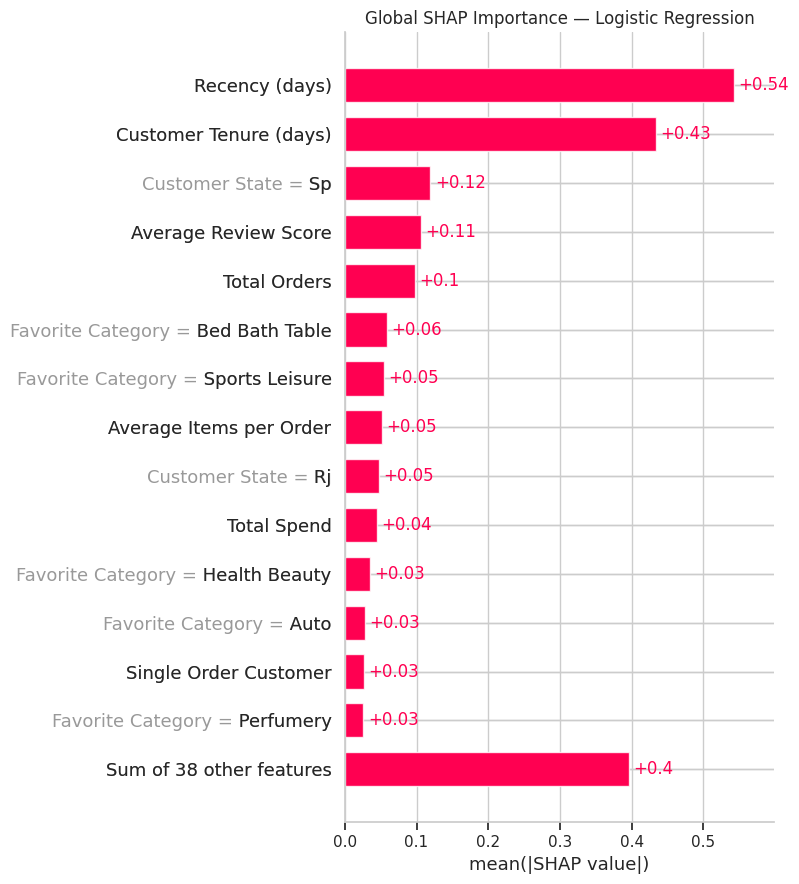

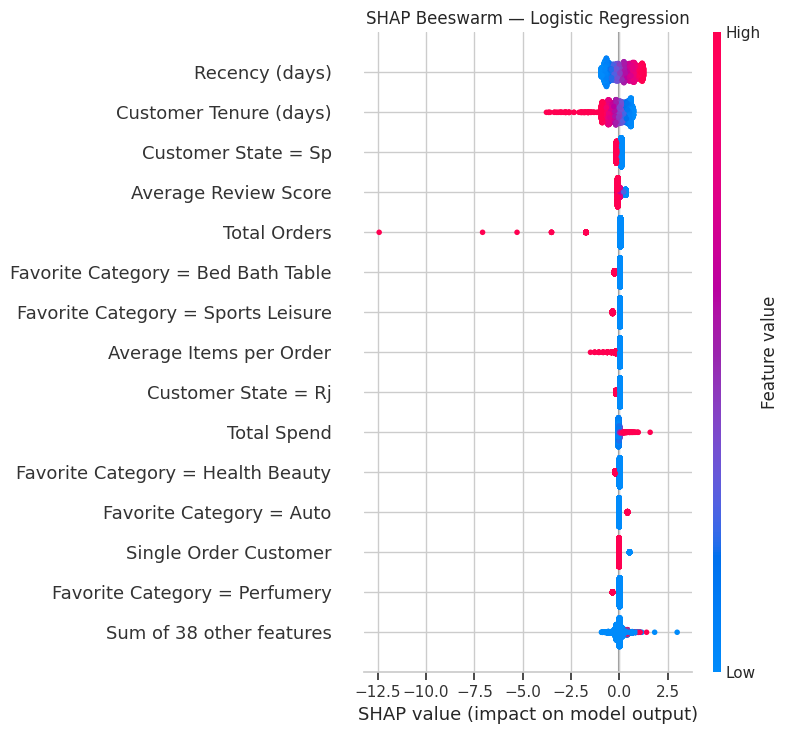


SHAP berdasarkan kelompok fitur bisnis:


,business_feature,mean_abs_shap,mean_signed_shap,average_direction
0,Recency,0.538901,0.122271,Secara neto mendorong prediksi Churn
1,Customer Tenure,0.427726,-0.112577,Secara neto menahan prediksi Churn
2,Favorite Category,0.210138,0.016617,Secara neto mendorong prediksi Churn
3,Average Review Score,0.106878,0.009675,Secara neto mendorong prediksi Churn
4,Customer State,0.099412,0.000482,Secara neto mendorong prediksi Churn
5,Total Orders,0.090265,0.014508,Secara neto mendorong prediksi Churn
6,Average Items per Order,0.053086,-0.003016,Secara neto menahan prediksi Churn
7,Total Spend,0.044763,-0.003349,Secara neto menahan prediksi Churn
8,Single Order Customer,0.025505,-0.004203,Secara neto menahan prediksi Churn
9,Payment Method,0.021926,0.000931,Secara neto mendorong prediksi Churn


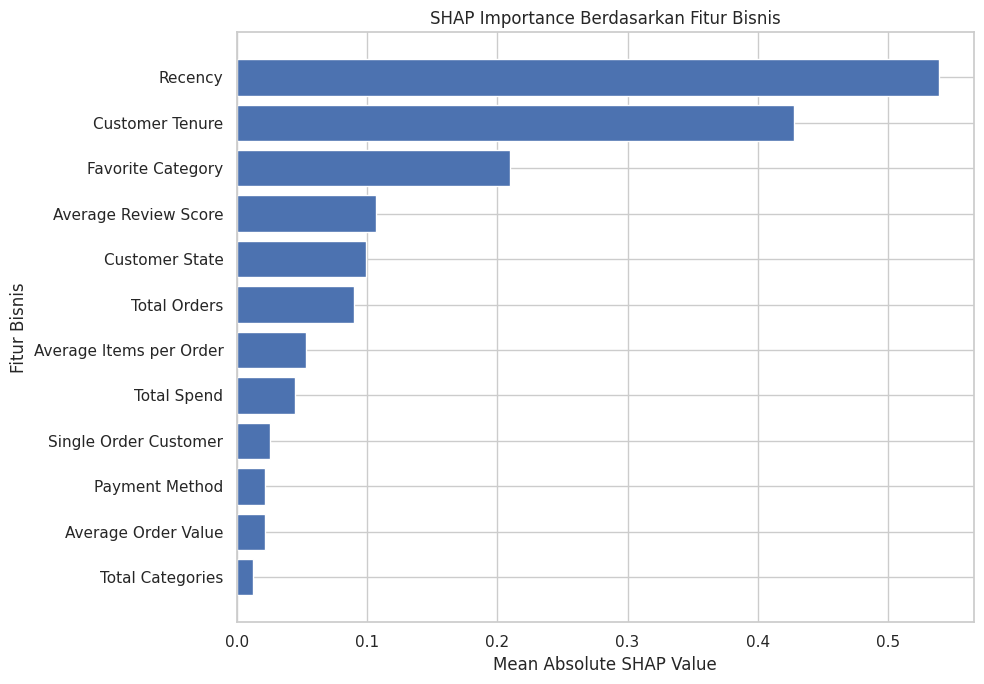


Contoh penjelasan SHAP setiap customer:


,customer_unique_id,shap_explained_model,top_churn_driver_1,top_churn_driver_1_value,top_churn_driver_2,top_churn_driver_2_value,top_churn_driver_3,top_churn_driver_3_value,top_protective_factor,top_protective_value
0,0000366f3b9a7992bf8c76cfdf3221e2,Logistic Regression,Customer Tenure,0.538331,Total Orders,0.053468,Average Items per Order,0.027851,Recency,-0.700174
1,0000b849f77a49e4a4ce2b2a4ca5be3f,Logistic Regression,Customer Tenure,0.510744,Total Orders,0.053468,Average Items per Order,0.027851,Recency,-0.663713
2,0004bd2a26a76fe21f786e4fbd80607f,Logistic Regression,Customer Tenure,0.216473,Favorite Category,0.054502,Total Orders,0.053468,Recency,-0.274795
3,00050ab1314c0e55a6ca13cf7181fecf,Logistic Regression,Customer Tenure,0.354412,Total Orders,0.053468,Average Items per Order,0.027851,Recency,-0.457100
4,00053a61a98854899e70ed204dd4bafe,Logistic Regression,Average Review Score,0.321126,Recency,0.162738,Total Spend,0.099009,Favorite Category,-0.317716
5,0005ef4cd20d2893f0d9fbd94d3c0d97,Logistic Regression,Average Review Score,0.321126,Customer State,0.068374,Total Orders,0.053468,Favorite Category,-0.317716
6,00090324bbad0e9342388303bb71ba0a,Logistic Regression,Customer Tenure,0.106121,Total Orders,0.053468,Average Items per Order,0.027851,Favorite Category,-0.226988
7,000949456b182f53c18b68d6babc79c1,Logistic Regression,Customer Tenure,0.382000,Total Orders,0.053468,Average Items per Order,0.027851,Recency,-0.493561
8,000c8bdb58a29e7115cfc257230fb21b,Logistic Regression,Recency,1.110725,Total Orders,0.053468,Average Items per Order,0.027851,Customer Tenure,-0.831866
9,000d460961d6dbfa3ec6c9f5805769e1,Logistic Regression,Recency,0.794730,Total Orders,0.053468,Average Items per Order,0.027851,Customer Tenure,-0.592771



Customer contoh untuk local SHAP:


,Example,customer_unique_id,churn_risk_score,actual_status
0,Highest Risk Score,b90f1d3b98edcabd42c810c0cfcf0424,0.929948,Churn
1,Lowest Risk Score,3e43e6105506432c953e165fb2acf44c,0.000042,Churn


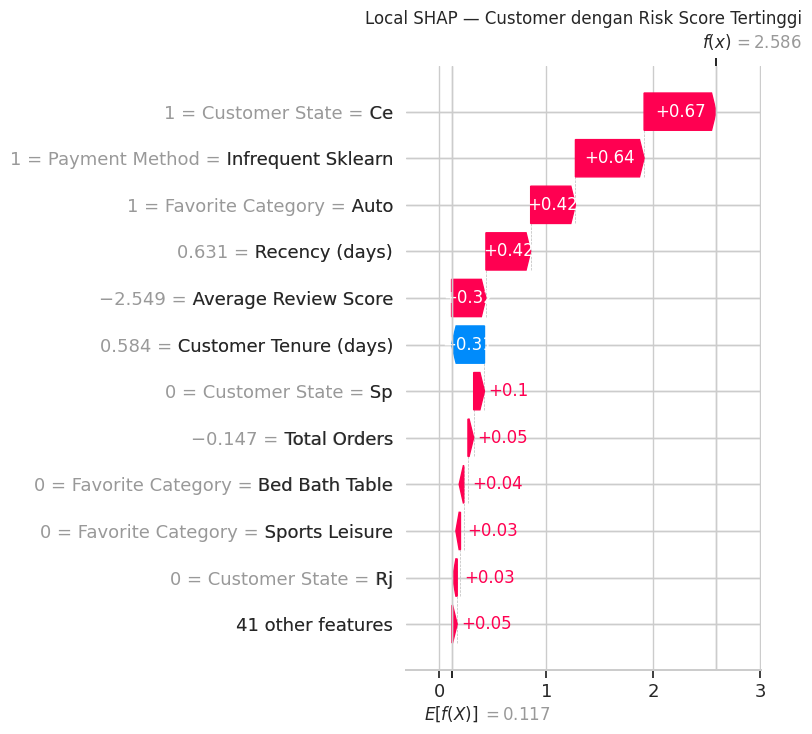

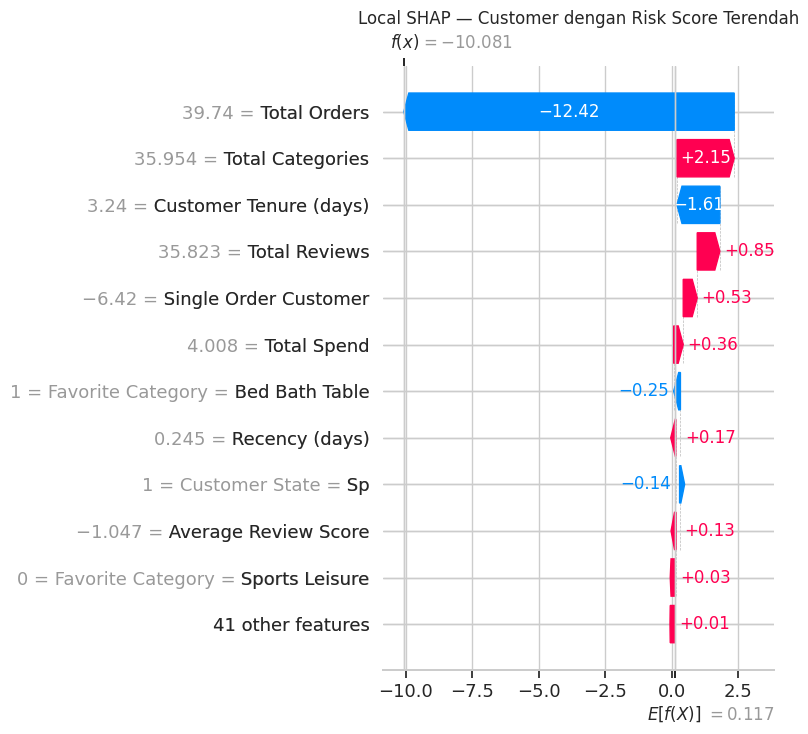


KESIMPULAN EXPLAINABLE AI
Model yang dijelaskan: Logistic Regression
Fitur bisnis SHAP terpenting: Recency
Catatan: nilai SHAP menjelaskan perilaku model dan bukan bukti hubungan sebab-akibat.


In [ ]:
import importlib.util
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)


# ============================================================
# 1. INSTALL DAN IMPORT SHAP
# ============================================================

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "shap"
    ])

import shap

print("SHAP version:", shap.__version__)


# ============================================================
# 2. MENGAMBIL MODEL TERBAIK HASIL VALIDATION
# ============================================================

if best_model_name not in trained_models:
    raise ValueError(
        f"Model terbaik adalah {best_model_name}, tetapi model tersebut "
        "tidak ditemukan pada trained_models."
    )

explained_model_name = best_model_name

explained_pipeline = trained_models[
    explained_model_name
]

explained_preprocessor = explained_pipeline.named_steps[
    "preprocessor"
]

explained_classifier = explained_pipeline.named_steps[
    "classifier"
]

print("\nModel yang akan dijelaskan:")
print(explained_model_name)

print("\nJenis classifier:")
print(type(explained_classifier).__name__)


# ============================================================
# 3. NAMA FITUR SETELAH PREPROCESSING
# ============================================================

transformed_feature_names = (
    explained_preprocessor.get_feature_names_out()
)


def readable_feature_name(feature_name):
    """
    Mengubah nama fitur hasil preprocessing menjadi
    nama yang lebih mudah dipahami.
    """

    raw_name = feature_name.split("__", 1)[-1]

    numeric_labels = {
        "recency_days": "Recency (days)",
        "total_orders": "Total Orders",
        "total_spend": "Total Spend",
        "average_order_value": "Average Order Value",
        "avg_days_between_orders": "Average Days Between Orders",
        "single_order_flag": "Single Order Customer",
        "avg_review_score": "Average Review Score",
        "total_reviews": "Total Reviews",
        "average_items_per_order": "Average Items per Order",
        "total_categories": "Total Categories",
        "customer_tenure_days": "Customer Tenure (days)"
    }

    if raw_name in numeric_labels:
        return numeric_labels[raw_name]

    prefixes = {
        "favorite_category_": "Favorite Category = ",
        "payment_method_": "Payment Method = ",
        "customer_state_": "Customer State = "
    }

    for prefix, label in prefixes.items():

        if raw_name.startswith(prefix):

            category_value = raw_name[
                len(prefix):
            ]

            return (
                label
                + category_value
                .replace("_", " ")
                .title()
            )

    return raw_name.replace("_", " ").title()


def business_feature_group(feature_name):
    """
    Mengelompokkan dummy variable ke fitur bisnis asal.
    """

    raw_name = feature_name.split("__", 1)[-1]

    if raw_name.startswith("favorite_category_"):
        return "Favorite Category"

    if raw_name.startswith("payment_method_"):
        return "Payment Method"

    if raw_name.startswith("customer_state_"):
        return "Customer State"

    feature_labels = {
        "recency_days": "Recency",
        "total_orders": "Total Orders",
        "total_spend": "Total Spend",
        "average_order_value": "Average Order Value",
        "avg_days_between_orders": "Average Days Between Orders",
        "single_order_flag": "Single Order Customer",
        "avg_review_score": "Average Review Score",
        "total_reviews": "Total Reviews",
        "average_items_per_order": "Average Items per Order",
        "total_categories": "Total Categories",
        "customer_tenure_days": "Customer Tenure"
    }

    return feature_labels.get(
        raw_name,
        raw_name.replace("_", " ").title()
    )


readable_feature_names = [
    readable_feature_name(feature_name)
    for feature_name in transformed_feature_names
]

feature_groups = [
    business_feature_group(feature_name)
    for feature_name in transformed_feature_names
]

feature_name_table = pd.DataFrame({
    "Original Feature": transformed_feature_names,
    "Readable Feature": readable_feature_names,
    "Business Group": feature_groups
})

print("\nContoh nama fitur hasil preprocessing:")

display(
    feature_name_table.head(20)
)


# ============================================================
# 4. TRANSFORMASI DATA UNTUK SHAP
# ============================================================

rng_shap = np.random.default_rng(SEED)

# Background dibatasi agar proses SHAP lebih ringan
background_size = min(
    500,
    len(X_calibration_raw)
)

background_index = rng_shap.choice(
    len(X_calibration_raw),
    size=background_size,
    replace=False
)

X_background = explained_preprocessor.transform(
    X_calibration_raw.iloc[
        background_index
    ]
)

X_holdout_explain = explained_preprocessor.transform(
    X_holdout_raw
)

X_background_dataframe = pd.DataFrame(
    X_background,
    columns=readable_feature_names
)

X_holdout_explain_dataframe = pd.DataFrame(
    X_holdout_explain,
    columns=readable_feature_names
)

print("\nJumlah background SHAP:", len(X_background_dataframe))
print("Jumlah customer holdout:", len(X_holdout_explain_dataframe))
print("Jumlah fitur:", X_holdout_explain_dataframe.shape[1])


# ============================================================
# 5. MEMILIH SHAP EXPLAINER
# ============================================================

if isinstance(
    explained_classifier,
    LogisticRegression
):

    shap_explainer_type = "LinearExplainer"

    background_masker = shap.maskers.Independent(
        X_background_dataframe,
        max_samples=background_size
    )

    shap_explainer = shap.LinearExplainer(
        explained_classifier,
        background_masker
    )

    raw_shap_explanation = shap_explainer(
        X_holdout_explain_dataframe
    )

    shap_values_array = np.asarray(
        raw_shap_explanation.values
    )

    shap_base_values = np.asarray(
        raw_shap_explanation.base_values
    )

elif isinstance(
    explained_classifier,
    (
        RandomForestClassifier,
        HistGradientBoostingClassifier
    )
):

    shap_explainer_type = "TreeExplainer"

    shap_explainer = shap.TreeExplainer(
        explained_classifier
    )

    raw_shap_explanation = shap_explainer(
        X_holdout_explain_dataframe
    )

    shap_values_array = np.asarray(
        raw_shap_explanation.values
    )

    shap_base_values = np.asarray(
        raw_shap_explanation.base_values
    )

    # Beberapa versi SHAP menghasilkan dimensi
    # terakhir untuk kelas Active dan Churn.
    if shap_values_array.ndim == 3:

        if shap_values_array.shape[-1] == 2:
            shap_values_array = (
                shap_values_array[:, :, 1]
            )

        elif shap_values_array.shape[0] == 2:
            shap_values_array = (
                shap_values_array[1]
            )

    if shap_base_values.ndim == 2:

        if shap_base_values.shape[-1] == 2:
            shap_base_values = (
                shap_base_values[:, 1]
            )

else:
    raise ValueError(
        "Jenis model belum didukung oleh Cell SHAP: "
        + type(explained_classifier).__name__
    )


if shap_values_array.ndim != 2:
    raise ValueError(
        "Dimensi SHAP values tidak sesuai: "
        + str(shap_values_array.shape)
    )

if shap_base_values.ndim == 0:
    shap_base_values = np.repeat(
        shap_base_values,
        len(X_holdout_explain_dataframe)
    )


shap_explanation = shap.Explanation(
    values=shap_values_array,
    base_values=shap_base_values,
    data=X_holdout_explain_dataframe.to_numpy(),
    feature_names=readable_feature_names
)

print("\nModel yang dijelaskan:", explained_model_name)
print("Jenis SHAP explainer:", shap_explainer_type)
print(
    "Jumlah customer yang dijelaskan:",
    f"{len(shap_explanation):,}"
)
print(
    "Jumlah fitur setelah preprocessing:",
    shap_values_array.shape[1]
)


# ============================================================
# 6. GLOBAL SHAP — DETAIL FITUR
# ============================================================

shap_global_detailed = pd.DataFrame({
    "feature": readable_feature_names,
    "original_transformed_feature": (
        transformed_feature_names
    ),
    "business_group": feature_groups,
    "mean_abs_shap": np.abs(
        shap_values_array
    ).mean(axis=0),
    "mean_signed_shap": (
        shap_values_array.mean(axis=0)
    )
})

shap_global_detailed = (
    shap_global_detailed
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_global_detailed[
    "average_direction"
] = np.where(
    shap_global_detailed[
        "mean_signed_shap"
    ] >= 0,
    "Secara neto mendorong prediksi Churn",
    "Secara neto menahan prediksi Churn"
)

shap_global_detailed.to_csv(
    OUTPUT_DIR / "shap_global_importance_detailed.csv",
    index=False
)

print("\n15 fitur SHAP terpenting:")

display(
    shap_global_detailed
    .head(15)
    .round(6)
)


# ============================================================
# 7. GLOBAL SHAP BAR PLOT
# ============================================================

plot_sample_size = min(
    5000,
    len(shap_explanation)
)

plot_index = rng_shap.choice(
    len(shap_explanation),
    size=plot_sample_size,
    replace=False
)

shap_plot_sample = shap_explanation[
    plot_index
]

shap.plots.bar(
    shap_plot_sample,
    max_display=15,
    show=False
)

plt.title(
    f"Global SHAP Importance — {explained_model_name}"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "shap_global_bar.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    shap_plot_sample,
    max_display=15,
    show=False
)

plt.title(
    f"SHAP Beeswarm — {explained_model_name}"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "shap_beeswarm.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. SHAP BERDASARKAN KELOMPOK FITUR BISNIS
# ============================================================

business_group_names = list(
    dict.fromkeys(feature_groups)
)

feature_groups_array = np.asarray(
    feature_groups
)

grouped_shap_values = np.column_stack([
    shap_values_array[
        :,
        feature_groups_array == group_name
    ].sum(axis=1)

    for group_name in business_group_names
])

shap_global_grouped = pd.DataFrame({
    "business_feature": business_group_names,
    "mean_abs_shap": np.abs(
        grouped_shap_values
    ).mean(axis=0),
    "mean_signed_shap": (
        grouped_shap_values.mean(axis=0)
    )
})

shap_global_grouped = (
    shap_global_grouped
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_global_grouped[
    "average_direction"
] = np.where(
    shap_global_grouped[
        "mean_signed_shap"
    ] >= 0,
    "Secara neto mendorong prediksi Churn",
    "Secara neto menahan prediksi Churn"
)

shap_global_grouped.to_csv(
    OUTPUT_DIR / "shap_global_importance_grouped.csv",
    index=False
)

print("\nSHAP berdasarkan kelompok fitur bisnis:")

display(
    shap_global_grouped.round(6)
)


top_grouped_shap = (
    shap_global_grouped
    .head(12)
    .sort_values("mean_abs_shap")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_grouped_shap["business_feature"],
    top_grouped_shap["mean_abs_shap"],
    color="#4C72B0"
)

plt.title(
    "SHAP Importance Berdasarkan Fitur Bisnis"
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Fitur Bisnis")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "shap_grouped_business_features.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. SHAP DRIVER SETIAP CUSTOMER
# ============================================================

row_numbers = np.arange(
    len(grouped_shap_values)
)

top_positive_index = np.argsort(
    -grouped_shap_values,
    axis=1
)[:, :3]

top_protective_index = np.argmin(
    grouped_shap_values,
    axis=1
)

customer_shap_drivers = holdout[
    ["customer_unique_id"]
].copy()

customer_shap_drivers[
    "shap_explained_model"
] = explained_model_name


# Pendorong churn hanya dicatat jika SHAP positif
for rank_number in range(3):

    selected_index = top_positive_index[
        :,
        rank_number
    ]

    selected_values = grouped_shap_values[
        row_numbers,
        selected_index
    ]

    customer_shap_drivers[
        f"top_churn_driver_{rank_number + 1}"
    ] = [
        (
            business_group_names[index]
            if value > 0
            else "Tidak ada pendorong positif"
        )
        for index, value in zip(
            selected_index,
            selected_values
        )
    ]

    customer_shap_drivers[
        f"top_churn_driver_{rank_number + 1}_value"
    ] = selected_values


# Faktor pelindung hanya dicatat jika SHAP negatif
top_protective_values = grouped_shap_values[
    row_numbers,
    top_protective_index
]

customer_shap_drivers[
    "top_protective_factor"
] = [
    (
        business_group_names[index]
        if value < 0
        else "Tidak ada faktor pelindung"
    )
    for index, value in zip(
        top_protective_index,
        top_protective_values
    )
]

customer_shap_drivers[
    "top_protective_value"
] = top_protective_values


customer_shap_drivers.to_csv(
    OUTPUT_DIR / "shap_customer_explanations.csv",
    index=False
)

print("\nContoh penjelasan SHAP setiap customer:")

display(
    customer_shap_drivers
    .head(10)
    .round(6)
)


# ============================================================
# 11. LOCAL SHAP EXPLANATION
# ============================================================

selected_probability = model_probabilities[
    best_model_name
]

highest_risk_position = int(
    np.argmax(selected_probability)
)

lowest_risk_position = int(
    np.argmin(selected_probability)
)

local_example_table = pd.DataFrame({
    "Example": [
        "Highest Risk Score",
        "Lowest Risk Score"
    ],
    "customer_unique_id": [
        holdout.iloc[
            highest_risk_position
        ]["customer_unique_id"],

        holdout.iloc[
            lowest_risk_position
        ]["customer_unique_id"]
    ],
    "churn_risk_score": [
        selected_probability[
            highest_risk_position
        ],

        selected_probability[
            lowest_risk_position
        ]
    ],
    "actual_status": [
        (
            "Churn"
            if y_holdout[
                highest_risk_position
            ] == 1
            else "Active"
        ),

        (
            "Churn"
            if y_holdout[
                lowest_risk_position
            ] == 1
            else "Active"
        )
    ]
})

print("\nCustomer contoh untuk local SHAP:")

display(
    local_example_table.round(6)
)


shap.plots.waterfall(
    shap_explanation[
        highest_risk_position
    ],
    max_display=12,
    show=False
)

plt.title(
    "Local SHAP — Customer dengan Risk Score Tertinggi"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "shap_waterfall_high_risk.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


shap.plots.waterfall(
    shap_explanation[
        lowest_risk_position
    ],
    max_display=12,
    show=False
)

plt.title(
    "Local SHAP — Customer dengan Risk Score Terendah"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "shap_waterfall_low_risk.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. KESIMPULAN CELL 18
# ============================================================

print("\n" + "=" * 65)
print("KESIMPULAN EXPLAINABLE AI")
print("=" * 65)

print("Model yang dijelaskan:", explained_model_name)

print(
    "Fitur bisnis SHAP terpenting:",
    shap_global_grouped.iloc[
        0
    ]["business_feature"]
)

print(
    "Catatan: nilai SHAP menjelaskan perilaku model "
    "dan bukan bukti hubungan sebab-akibat."
)

## 19. Responsible AI evaluation dan model card

Tahap ini mendokumentasikan keandalan dan batas penggunaan model. Evaluasi
mencakup calibration, bootstrap confidence interval, dan pemeriksaan performa
berdasarkan state yang memiliki jumlah observasi memadai. Pemeriksaan state
bukan bukti fairness demografis karena Dataset Olist tidak menyediakan atribut
sensitif seperti gender atau ras.

Model hanya digunakan untuk **pendukung prioritas retensi**. Hasil probabilitas
dan SHAP tidak boleh digunakan sebagai keputusan otomatis yang merugikan
customer.


Model yang dievaluasi: Logistic Regression
Threshold keputusan: 0.42
Jumlah data holdout: 38,838

Hasil evaluasi calibration:


,metric,value
0,Selected Model Brier Score,0.223822
1,Prevalence Baseline Brier Score,0.006654
2,Active Prevalence / PR-AUC Baseline,0.006694
3,Selected Model PR-AUC Active,0.019558
4,PR-AUC Active Improvement over Baseline,2.921486



Interpretasi calibration:
Model belum terkalibrasi dengan baik karena Brier Score model lebih besar daripada baseline.
Nilai prediksi digunakan sebagai relative churn risk score, bukan probabilitas absolut pelanggan akan churn.

Tabel calibration curve:


,mean_predicted_probability,observed_churn_rate
0,0.332202,0.981977
1,0.440951,0.991246
2,0.476951,0.995623
3,0.504432,0.995107
4,0.528916,0.995366
5,0.553635,0.993821
6,0.580424,0.995622
7,0.611147,0.992276
8,0.648869,0.996395
9,0.719038,0.995623


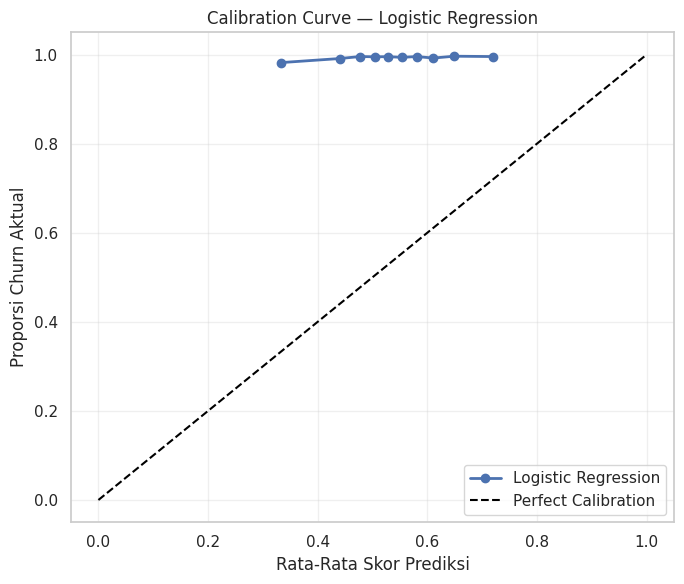


Bootstrap 95% Confidence Interval (300 sampel berhasil):


,metric,mean,ci_2_5_percent,ci_97_5_percent
0,roc_auc,0.609561,0.570684,0.648251
1,pr_auc_active,0.021576,0.012883,0.033591
2,balanced_accuracy,0.588489,0.558757,0.617421
3,mcc,0.047347,0.031401,0.063241



Audit performa berdasarkan customer state:


,customer_state,total_customers,active_customers,churn_customers,balanced_accuracy,recall_active,roc_auc,pr_auc_active
0,SP,16625,133,16492,0.6015,0.3534,0.6101,0.0233
1,RJ,4843,31,4812,0.5935,0.2903,0.5432,0.0285
2,MG,4595,22,4573,0.5758,0.2273,0.5493,0.0085
3,RS,2063,7,2056,0.6727,0.4286,0.7146,0.0841
4,PR,1989,13,1976,0.5516,0.1538,0.5122,0.0166
5,SC,1456,12,1444,0.5880,0.2500,0.7074,0.0222
6,BA,1289,9,1280,0.5395,0.1111,0.7782,0.0351
7,DF,845,7,838,0.4899,0.0000,0.4792,0.0118
8,GO,810,7,803,0.5465,0.1429,0.7947,0.0316
9,ES,789,5,784,0.4828,0.0000,0.5477,0.0079



Ringkasan Responsible AI Evaluation:


,Indicator,Value
0,Selected Model,Logistic Regression
1,Decision Threshold,0.42
2,Balanced Accuracy Holdout,0.589086
3,ROC-AUC Holdout,0.609699
4,PR-AUC Active Holdout,0.019558
5,Recall Active Holdout,0.280769
6,MCC Holdout,0.047638
7,Brier Score Model,0.223822
8,Brier Score Baseline,0.006654
9,Calibration Status,Model belum terkalibrasi dengan baik karena Br...



Responsible AI Model Card:


,Component,Description
0,Model,Logistic Regression
1,Intended Use,Pendukung penentuan prioritas program retensi ...
2,Target Definition,Pelanggan dianggap churn apabila tidak melakuk...
3,Selection Criterion,Model dipilih berdasarkan PR-AUC kelas Active ...
4,Decision Threshold,0.42
5,Explainability,Menggunakan global dan local explanation berba...
6,Reliability Evaluation,"Dievaluasi menggunakan time-based holdout, cal..."
7,Privacy,Menggunakan customer_unique_id yang telah dian...
8,Human Oversight,Keputusan retensi akhir harus ditinjau oleh ma...
9,Prohibited Use,Model tidak digunakan untuk keputusan otomatis...



KESIMPULAN RESPONSIBLE AI EVALUATION
Model: Logistic Regression
ROC-AUC holdout: 0.6097
Balanced Accuracy holdout: 0.5891
PR-AUC Active holdout: 0.0196
Peningkatan PR-AUC Active dibanding baseline: 2.92 kali
Model belum terkalibrasi dengan baik karena Brier Score model lebih besar daripada baseline.
Hasil model digunakan sebagai relative churn risk score untuk mendukung prioritas retensi dan bukan sebagai keputusan otomatis.


In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    brier_score_loss,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    matthews_corrcoef,
    recall_score
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. MENGAMBIL HASIL MODEL TERPILIH
# ============================================================

selected_probability = model_probabilities[
    best_model_name
]

selected_threshold = model_thresholds[
    best_model_name
]

selected_prediction = (
    selected_probability >= selected_threshold
).astype(int)

print("Model yang dievaluasi:", best_model_name)
print(
    "Threshold keputusan:",
    round(selected_threshold, 4)
)
print(
    "Jumlah data holdout:",
    f"{len(y_holdout):,}"
)


# ============================================================
# 2. CALIBRATION DAN BRIER SCORE
# ============================================================

# Probabilitas baseline mengikuti proporsi kelas churn
# pada dataset calibration.
baseline_churn_probability = float(
    y_calibration.mean()
)

baseline_probability = np.repeat(
    baseline_churn_probability,
    len(y_holdout)
)

# Semakin kecil Brier Score, semakin baik kalibrasi model.
selected_brier_score = brier_score_loss(
    y_holdout,
    selected_probability
)

baseline_brier_score = brier_score_loss(
    y_holdout,
    baseline_probability
)

# Karena kelas Active adalah kelas minoritas,
# prevalensi Active menjadi baseline PR-AUC Active.
active_prevalence = float(
    (y_holdout == 0).mean()
)

selected_pr_auc_active = average_precision_score(
    1 - y_holdout,
    1 - selected_probability
)

pr_auc_improvement = (
    selected_pr_auc_active / active_prevalence
    if active_prevalence > 0
    else np.nan
)


calibration_metrics = pd.DataFrame({
    "metric": [
        "Selected Model Brier Score",
        "Prevalence Baseline Brier Score",
        "Active Prevalence / PR-AUC Baseline",
        "Selected Model PR-AUC Active",
        "PR-AUC Active Improvement over Baseline"
    ],
    "value": [
        selected_brier_score,
        baseline_brier_score,
        active_prevalence,
        selected_pr_auc_active,
        pr_auc_improvement
    ]
})

calibration_metrics.to_csv(
    OUTPUT_DIR / "calibration_metrics.csv",
    index=False
)

print("\nHasil evaluasi calibration:")

display(
    calibration_metrics.round(6)
)


# ============================================================
# 3. INTERPRETASI HASIL CALIBRATION
# ============================================================

if selected_brier_score < baseline_brier_score:

    calibration_status = (
        "Model memiliki Brier Score lebih rendah daripada baseline."
    )

    score_interpretation = (
        "Nilai model dapat digunakan sebagai probabilitas prediksi, "
        "tetapi tetap harus diinterpretasikan secara hati-hati."
    )

else:

    calibration_status = (
        "Model belum terkalibrasi dengan baik karena Brier Score "
        "model lebih besar daripada baseline."
    )

    score_interpretation = (
        "Nilai prediksi digunakan sebagai relative churn risk score, "
        "bukan probabilitas absolut pelanggan akan churn."
    )

print("\nInterpretasi calibration:")
print(calibration_status)
print(score_interpretation)


# ============================================================
# 4. CALIBRATION CURVE
# ============================================================

fraction_of_positives, mean_predicted_value = (
    calibration_curve(
        y_holdout,
        selected_probability,
        n_bins=10,
        strategy="quantile"
    )
)

calibration_curve_dataframe = pd.DataFrame({
    "mean_predicted_probability": (
        mean_predicted_value
    ),
    "observed_churn_rate": (
        fraction_of_positives
    )
})

calibration_curve_dataframe.to_csv(
    OUTPUT_DIR / "calibration_curve.csv",
    index=False
)

print("\nTabel calibration curve:")

display(
    calibration_curve_dataframe.round(6)
)


plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    linewidth=2,
    label=best_model_name
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

plt.xlabel("Rata-Rata Skor Prediksi")
plt.ylabel("Proporsi Churn Aktual")
plt.title(
    f"Calibration Curve — {best_model_name}"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "calibration_curve.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. BOOTSTRAP CONFIDENCE INTERVAL
# ============================================================

bootstrap_rng = np.random.default_rng(SEED)

bootstrap_results = []

number_bootstrap = 300

for bootstrap_number in range(number_bootstrap):

    sample_index = bootstrap_rng.choice(
        len(y_holdout),
        size=len(y_holdout),
        replace=True
    )

    sample_actual = y_holdout[
        sample_index
    ]

    sample_probability = selected_probability[
        sample_index
    ]

    sample_prediction = selected_prediction[
        sample_index
    ]

    # ROC-AUC tidak bisa dihitung jika hanya terdapat
    # satu kelas dalam sampel bootstrap.
    if len(np.unique(sample_actual)) < 2:
        continue

    bootstrap_results.append({
        "roc_auc": roc_auc_score(
            sample_actual,
            sample_probability
        ),
        "pr_auc_active": average_precision_score(
            1 - sample_actual,
            1 - sample_probability
        ),
        "balanced_accuracy": (
            balanced_accuracy_score(
                sample_actual,
                sample_prediction
            )
        ),
        "mcc": matthews_corrcoef(
            sample_actual,
            sample_prediction
        )
    })


bootstrap_dataframe = pd.DataFrame(
    bootstrap_results
)

bootstrap_summary_rows = []

for metric_name in bootstrap_dataframe.columns:

    bootstrap_summary_rows.append({
        "metric": metric_name,
        "mean": bootstrap_dataframe[
            metric_name
        ].mean(),
        "ci_2_5_percent": bootstrap_dataframe[
            metric_name
        ].quantile(0.025),
        "ci_97_5_percent": bootstrap_dataframe[
            metric_name
        ].quantile(0.975)
    })


bootstrap_confidence_intervals = pd.DataFrame(
    bootstrap_summary_rows
)

bootstrap_confidence_intervals.to_csv(
    OUTPUT_DIR / "bootstrap_confidence_intervals.csv",
    index=False
)

print(
    "\nBootstrap 95% Confidence Interval "
    f"({len(bootstrap_dataframe)} sampel berhasil):"
)

display(
    bootstrap_confidence_intervals.round(6)
)


# ============================================================
# 6. AUDIT PERFORMA BERDASARKAN CUSTOMER STATE
# ============================================================

geographic_audit_rows = []

for state_name, state_index in (
    holdout
    .groupby("customer_state")
    .groups
    .items()
):

    state_index = np.asarray(
        list(state_index),
        dtype=int
    )

    state_actual = y_holdout[
        state_index
    ]

    # State hanya dianalisis jika mempunyai minimal:
    # - 500 pelanggan;
    # - 5 pelanggan Active.
    #
    # Hal ini dilakukan agar metrik tidak terlalu labil.
    if (
        len(state_index) < 500
        or (state_actual == 0).sum() < 5
    ):
        continue

    state_probability = selected_probability[
        state_index
    ]

    state_prediction = (
        state_probability >= selected_threshold
    ).astype(int)

    # Memastikan terdapat dua kelas.
    if len(np.unique(state_actual)) < 2:
        continue

    geographic_audit_rows.append({
        "customer_state": state_name,
        "total_customers": len(state_index),
        "active_customers": int(
            (state_actual == 0).sum()
        ),
        "churn_customers": int(
            (state_actual == 1).sum()
        ),
        "balanced_accuracy": (
            balanced_accuracy_score(
                state_actual,
                state_prediction
            )
        ),
        "recall_active": recall_score(
            state_actual,
            state_prediction,
            pos_label=0,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            state_actual,
            state_probability
        ),
        "pr_auc_active": (
            average_precision_score(
                1 - state_actual,
                1 - state_probability
            )
        )
    })


geographic_performance_audit = pd.DataFrame(
    geographic_audit_rows
)

if not geographic_performance_audit.empty:

    geographic_performance_audit = (
        geographic_performance_audit
        .sort_values(
            "total_customers",
            ascending=False
        )
        .reset_index(drop=True)
    )

else:

    geographic_performance_audit = pd.DataFrame(
        columns=[
            "customer_state",
            "total_customers",
            "active_customers",
            "churn_customers",
            "balanced_accuracy",
            "recall_active",
            "roc_auc",
            "pr_auc_active"
        ]
    )


geographic_performance_audit.to_csv(
    OUTPUT_DIR / "geographic_performance_audit.csv",
    index=False
)

print("\nAudit performa berdasarkan customer state:")

display(
    geographic_performance_audit.round(4)
)


# ============================================================
# 7. RINGKASAN HASIL MODEL TERPILIH
# ============================================================

selected_result_row = metrics_dataframe[
    metrics_dataframe["model"] == best_model_name
].iloc[0]

responsible_ai_summary = pd.DataFrame({
    "Indicator": [
        "Selected Model",
        "Decision Threshold",
        "Balanced Accuracy Holdout",
        "ROC-AUC Holdout",
        "PR-AUC Active Holdout",
        "Recall Active Holdout",
        "MCC Holdout",
        "Brier Score Model",
        "Brier Score Baseline",
        "Calibration Status"
    ],
    "Value": [
        best_model_name,
        selected_threshold,
        selected_result_row[
            "balanced_accuracy"
        ],
        selected_result_row[
            "roc_auc"
        ],
        selected_result_row[
            "pr_auc_active"
        ],
        selected_result_row[
            "recall_active"
        ],
        selected_result_row[
            "mcc"
        ],
        selected_brier_score,
        baseline_brier_score,
        calibration_status
    ]
})

responsible_ai_summary.to_csv(
    OUTPUT_DIR / "responsible_ai_summary.csv",
    index=False
)

print("\nRingkasan Responsible AI Evaluation:")

display(
    responsible_ai_summary.round(6)
)


# ============================================================
# 8. RESPONSIBLE AI MODEL CARD
# ============================================================

responsible_ai_model_card = pd.DataFrame({
    "Component": [
        "Model",
        "Intended Use",
        "Target Definition",
        "Selection Criterion",
        "Decision Threshold",
        "Explainability",
        "Reliability Evaluation",
        "Privacy",
        "Human Oversight",
        "Prohibited Use",
        "Main Limitation",
        "Causality Warning"
    ],
    "Description": [
        best_model_name,

        (
            "Pendukung penentuan prioritas program "
            "retensi pelanggan."
        ),

        (
            "Pelanggan dianggap churn apabila tidak melakukan "
            "pembelian kembali dalam 90 hari setelah cutoff."
        ),

        (
            "Model dipilih berdasarkan PR-AUC kelas Active "
            "tertinggi pada validation set."
        ),

        str(round(selected_threshold, 4)),

        (
            "Menggunakan global dan local explanation "
            "berbasis SHAP."
        ),

        (
            "Dievaluasi menggunakan time-based holdout, "
            "calibration, bootstrap confidence interval, "
            "dan geographic performance audit."
        ),

        (
            "Menggunakan customer_unique_id yang telah "
            "dianonimkan dan tidak melakukan re-identification."
        ),

        (
            "Keputusan retensi akhir harus ditinjau "
            "oleh manusia."
        ),

        (
            "Model tidak digunakan untuk keputusan otomatis "
            "yang menolak, mengeluarkan, atau memberikan "
            "perlakuan merugikan kepada pelanggan."
        ),

        (
            "Dataset memiliki class imbalance ekstrem dan "
            "jumlah pelanggan repeat order yang sangat rendah."
        ),

        (
            "SHAP menjelaskan perilaku model dan tidak "
            "membuktikan hubungan sebab-akibat."
        )
    ]
})


# ============================================================
# 9. MENAMBAHKAN INFORMASI KALIBRASI KE MODEL CARD
# ============================================================

additional_model_card = pd.DataFrame({/
    "Component": [
        "Probability Calibration",
        "Score Interpretation"
    ],
    "Description": [
        (
            f"Model belum terkalibrasi dengan baik. "
            f"Brier Score model = {selected_brier_score:.4f}, "
            f"sedangkan baseline = {baseline_brier_score:.4f}."
            if selected_brier_score >= baseline_brier_score
            else
            (
                f"Brier Score model = {selected_brier_score:.4f}, "
                f"lebih rendah daripada baseline "
                f"{baseline_brier_score:.4f}."
            )
        ),

        score_interpretation
    ]
})


responsible_ai_model_card = pd.concat(
    [
        responsible_ai_model_card,
        additional_model_card
    ],
    ignore_index=True
)


# ============================================================
# 10. MENYIMPAN MODEL CARD FINAL
# ============================================================

responsible_ai_model_card.to_csv(
    OUTPUT_DIR / "responsible_ai_model_card.csv",
    index=False
)

print("\nResponsible AI Model Card:")

display(responsible_ai_model_card)


# ============================================================
# 11. KESIMPULAN OTOMATIS CELL 19
# ============================================================

print("\n" + "=" * 65)
print("KESIMPULAN RESPONSIBLE AI EVALUATION")
print("=" * 65)

print("Model:", best_model_name)

print(
    "ROC-AUC holdout:",
    round(
        selected_result_row["roc_auc"],
        4
    )
)

print(
    "Balanced Accuracy holdout:",
    round(
        selected_result_row[
            "balanced_accuracy"
        ],
        4
    )
)

print(
    "PR-AUC Active holdout:",
    round(
        selected_result_row[
            "pr_auc_active"
        ],
        4
    )
)

print(
    "Peningkatan PR-AUC Active dibanding baseline:",
    round(pr_auc_improvement, 2),
    "kali"
)

print(calibration_status)

print(
    "Hasil model digunakan sebagai relative churn risk score "
    "untuk mendukung prioritas retensi dan bukan sebagai "
    "keputusan otomatis."
)

## 20. Prediksi customer, SHAP drivers, relative risk, RFM, dan dashboard

Marketing Dashboard menggabungkan probabilitas churn, threshold keputusan,
relative risk, RFM, dan faktor utama hasil SHAP. Penjelasan digunakan sebagai
pendukung keputusan; keputusan retensi akhir tetap memerlukan human oversight

Model untuk dashboard: Logistic Regression
Threshold keputusan: 0.42
Batas relative risk dari validation: 0.5061 dan 0.6097
Catatan: nilai model digunakan sebagai relative churn risk score, bukan probabilitas absolut.

Sales KPI:


,Metric,Value
0,Total Orders,9.647800e+04
1,Total Customers,9.335800e+04
2,Product Revenue,1.322150e+07
3,Gross Order Value Including Freight,1.541977e+07
4,Average Order Value Including Freight,1.598268e+02
5,Average Review Score,4.156187e+00
6,Total Freight,2.198276e+06



Risk Segment Summary:


,risk_segment,total_customers,actual_churn_rate,average_churn_risk_score,average_total_spend
0,Relative High Risk,9842,0.9952,0.6703,197.3952
1,Relative Low Risk,13814,0.9907,0.4295,144.9368
2,Relative Medium Risk,15182,0.9944,0.5552,153.1067



RFM Segment Summary:


,rfm_segment,total_customers,actual_churn_rate,average_churn_risk_score,average_total_spend,average_orders
0,At-Risk Loyal,9,0.7778,0.0769,345.0389,3.2222
1,Big Spenders,3376,0.9935,0.5275,293.9768,1.1206
2,Champions,33,0.8788,0.0515,527.0067,3.1818
3,Lost / Hibernating,6335,0.9945,0.5800,54.9141,1.0000
4,New / Recent Customers,15313,0.9919,0.5041,166.0698,1.0000
5,Regular,13772,0.9947,0.5651,171.7627,1.0254



Contoh Marketing Dashboard:


,customer_unique_id,recency_days,total_orders,total_spend,churn_risk_score,decision_threshold,churn_prediction,risk_segment,top_churn_driver_1,top_churn_driver_2,top_churn_driver_3,top_protective_factor,R_score,F_score,M_score,RFM_score,rfm_segment
0,0000366f3b9a7992bf8c76cfdf3221e2,21,1,141.90,0.399398,0.42,0,Relative Low Risk,Customer Tenure,Total Orders,Average Items per Order,Recency,5,1,4,514,New / Recent Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,24,1,27.19,0.436622,0.42,1,Relative Low Risk,Customer Tenure,Total Orders,Average Items per Order,Recency,5,1,1,511,New / Recent Customers
2,0004bd2a26a76fe21f786e4fbd80607f,56,1,166.98,0.520947,0.42,1,Relative Medium Risk,Customer Tenure,Favorite Category,Total Orders,Recency,4,1,4,414,New / Recent Customers
3,00050ab1314c0e55a6ca13cf7181fecf,41,1,35.38,0.494107,0.42,1,Relative Low Risk,Customer Tenure,Total Orders,Average Items per Order,Recency,4,1,1,411,New / Recent Customers
4,00053a61a98854899e70ed204dd4bafe,92,1,419.18,0.536383,0.42,1,Relative Medium Risk,Average Review Score,Recency,Total Spend,Favorite Category,3,1,5,315,Big Spenders
5,0005ef4cd20d2893f0d9fbd94d3c0d97,80,1,129.76,0.561282,0.42,1,Relative Medium Risk,Average Review Score,Customer State,Total Orders,Favorite Category,3,1,3,313,Regular
6,00090324bbad0e9342388303bb71ba0a,68,1,63.66,0.429299,0.42,1,Relative Low Risk,Customer Tenure,Total Orders,Average Items per Order,Favorite Category,4,1,2,412,New / Recent Customers
7,000949456b182f53c18b68d6babc79c1,38,1,82.05,0.478735,0.42,1,Relative Low Risk,Customer Tenure,Total Orders,Average Items per Order,Recency,4,1,2,412,New / Recent Customers
8,000c8bdb58a29e7115cfc257230fb21b,170,1,29.00,0.533240,0.42,1,Relative Medium Risk,Recency,Total Orders,Average Items per Order,Customer Tenure,1,1,1,111,Lost / Hibernating
9,000d460961d6dbfa3ec6c9f5805769e1,144,1,36.68,0.539151,0.42,1,Relative Medium Risk,Recency,Total Orders,Average Items per Order,Customer Tenure,1,1,1,111,Lost / Hibernating


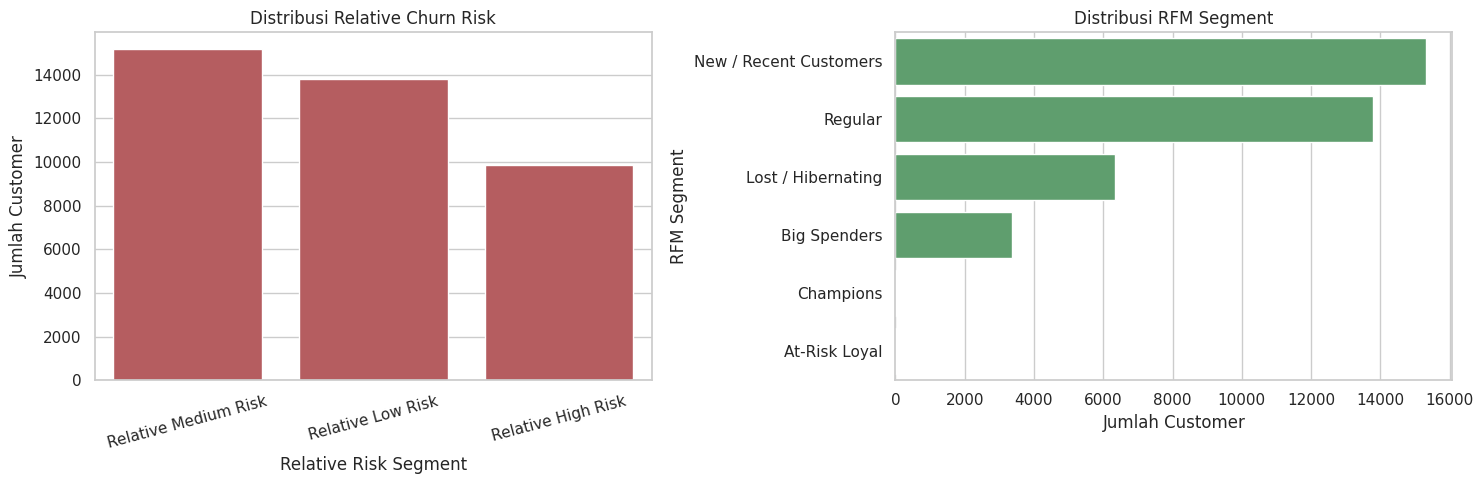


Distribusi faktor pendorong churn:


,business_feature,total_appearances
0,Total Orders,28275
1,Recency,20750
2,Favorite Category,17779
3,Customer Tenure,16253
4,Average Items per Order,9906
5,Average Review Score,8988
6,Customer State,7991
7,Total Spend,3875
8,Single Order Customer,781
9,Average Order Value,617


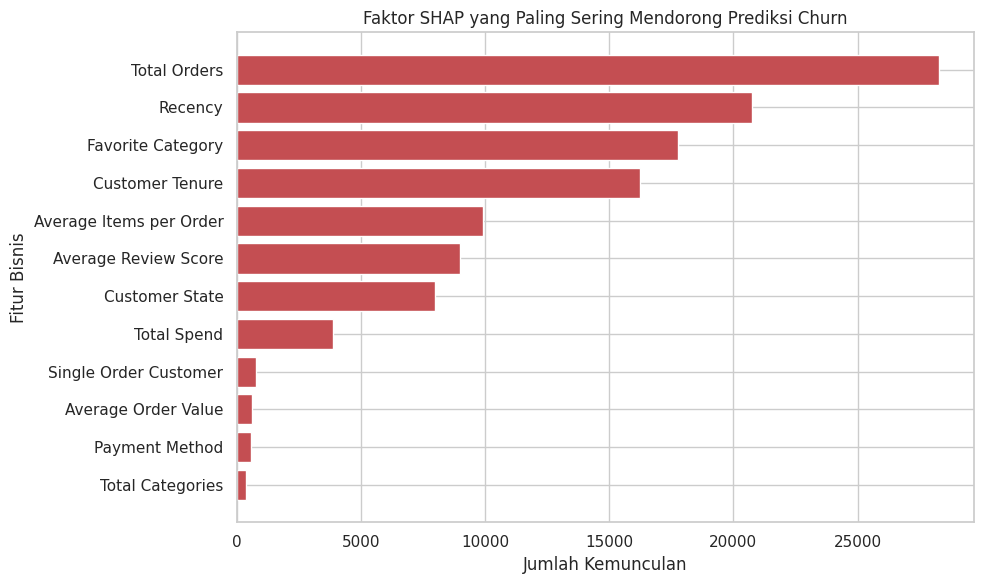


Marketing dashboard berhasil disimpan: /content/olist_outputs/marketing_churn_dashboard.csv
Distribusi SHAP berhasil disimpan: /content/olist_outputs/shap_driver_distribution.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. HASIL MODEL TERPILIH DARI VALIDATION
# ============================================================

best_probability = model_probabilities[
    best_model_name
]

best_threshold = model_thresholds[
    best_model_name
]

best_prediction = (
    best_probability >= best_threshold
).astype(int)


# ============================================================
# 2. MEMBENTUK MARKETING DASHBOARD
# ============================================================

marketing_dashboard = (
    holdout
    .reset_index(drop=True)
    .copy()
)

original_customer_order = marketing_dashboard[
    "customer_unique_id"
].copy()

marketing_dashboard = marketing_dashboard.merge(
    customer_shap_drivers,
    on="customer_unique_id",
    how="left",
    validate="one_to_one",
    sort=False
)

# Memastikan urutan customer tidak berubah setelah merge
assert original_customer_order.equals(
    marketing_dashboard[
        "customer_unique_id"
    ]
), (
    "Urutan customer berubah setelah proses merge SHAP."
)


# Kolom lama dipertahankan agar kode sebelumnya tetap kompatibel
marketing_dashboard[
    "churn_probability"
] = best_probability

# Nama yang digunakan untuk interpretasi dan dashboard
marketing_dashboard[
    "churn_risk_score"
] = best_probability

marketing_dashboard[
    "decision_threshold"
] = best_threshold

marketing_dashboard[
    "churn_prediction"
] = best_prediction

marketing_dashboard[
    "actual_status"
] = np.where(
    marketing_dashboard["is_churn"] == 1,
    "Churn",
    "Active"
)

marketing_dashboard[
    "predicted_status"
] = np.where(
    marketing_dashboard[
        "churn_prediction"
    ] == 1,
    "Churn",
    "Active"
)

marketing_dashboard[
    "selected_model"
] = best_model_name

marketing_dashboard[
    "explanation_method"
] = "SHAP"

marketing_dashboard[
    "score_interpretation"
] = (
    "Relative churn risk score; not an absolute probability"
)

marketing_dashboard[
    "human_oversight_note"
] = (
    "Keputusan retensi memerlukan peninjauan manusia; "
    "SHAP bukan bukti hubungan sebab-akibat."
)


# ============================================================
# 3. RELATIVE RISK SEGMENT
# Batas dipelajari dari validation, bukan holdout.
# ============================================================

validation_best_probability = validation_probabilities[
    best_model_name
]

risk_low_cutoff, risk_high_cutoff = np.quantile(
    validation_best_probability,
    [0.40, 0.75]
)

marketing_dashboard[
    "risk_segment"
] = np.select(
    [
        marketing_dashboard[
            "churn_risk_score"
        ] <= risk_low_cutoff,

        marketing_dashboard[
            "churn_risk_score"
        ] <= risk_high_cutoff
    ],
    [
        "Relative Low Risk",
        "Relative Medium Risk"
    ],
    default="Relative High Risk"
)

marketing_dashboard[
    "risk_low_cutoff"
] = risk_low_cutoff

marketing_dashboard[
    "risk_high_cutoff"
] = risk_high_cutoff

marketing_dashboard[
    "risk_definition"
] = (
    "Relative risk based on validation score quantiles"
)


# ============================================================
# 4. RFM SCORING
# ============================================================

def percentile_score(
    series,
    higher_is_better=True
):
    """
    Membentuk skor 1–5 berdasarkan percentile.
    """

    percentile = series.rank(
        method="average",
        pct=True
    )

    score = (
        np.ceil(percentile * 5)
        .clip(1, 5)
        .astype(int)
    )

    if not higher_is_better:
        score = 6 - score

    return score


def frequency_score(total_orders):
    """
    Customer dengan jumlah order yang sama
    memperoleh frequency score yang sama.
    """

    return np.select(
        [
            total_orders <= 1,
            total_orders == 2
        ],
        [
            1,
            3
        ],
        default=5
    ).astype(int)


marketing_dashboard[
    "R_score"
] = percentile_score(
    marketing_dashboard[
        "recency_days"
    ],
    higher_is_better=False
)

marketing_dashboard[
    "F_score"
] = frequency_score(
    marketing_dashboard[
        "total_orders"
    ]
)

marketing_dashboard[
    "M_score"
] = percentile_score(
    marketing_dashboard[
        "total_spend"
    ],
    higher_is_better=True
)

marketing_dashboard[
    "RFM_score"
] = (
    marketing_dashboard[
        "R_score"
    ].astype(str)
    + marketing_dashboard[
        "F_score"
    ].astype(str)
    + marketing_dashboard[
        "M_score"
    ].astype(str)
)

marketing_dashboard[
    "RFM_sum"
] = marketing_dashboard[
    [
        "R_score",
        "F_score",
        "M_score"
    ]
].sum(axis=1)


# ============================================================
# 5. RFM SEGMENTATION
# ============================================================

def assign_rfm_segment(row):

    recency = row["R_score"]
    frequency = row["F_score"]
    monetary = row["M_score"]

    if (
        recency >= 4
        and frequency >= 4
        and monetary >= 4
    ):
        return "Champions"

    if (
        recency >= 4
        and frequency <= 2
    ):
        return "New / Recent Customers"

    if (
        recency <= 2
        and frequency >= 4
    ):
        return "At-Risk Loyal"

    if (
        recency <= 2
        and frequency <= 2
        and monetary <= 2
    ):
        return "Lost / Hibernating"

    if (
        recency >= 3
        and monetary >= 4
    ):
        return "Big Spenders"

    return "Regular"


marketing_dashboard[
    "rfm_segment"
] = marketing_dashboard.apply(
    assign_rfm_segment,
    axis=1
)


# ============================================================
# 6. SALES KPI
# ============================================================

sales_kpi = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Customers",
        "Product Revenue",
        "Gross Order Value Including Freight",
        "Average Order Value Including Freight",
        "Average Review Score",
        "Total Freight"
    ],
    "Value": [
        fact["order_id"].nunique(),
        fact["customer_unique_id"].nunique(),
        fact["items_price"].sum(),
        fact["order_total_value"].sum(),
        fact["order_total_value"].mean(),
        fact["review_score"].mean(),
        fact["freight_value"].sum()
    ]
})

sales_kpi.to_csv(
    OUTPUT_DIR / "sales_kpi_summary.csv",
    index=False
)

monthly_transaction.to_csv(
    OUTPUT_DIR / "monthly_sales_trend.csv",
    index=False
)

category_performance.to_csv(
    OUTPUT_DIR / "category_performance.csv",
    index=False
)


# ============================================================
# 7. RFM DAN RISK SUMMARY
# ============================================================

rfm_summary = (
    marketing_dashboard
    .groupby(
        "rfm_segment",
        as_index=False,
        observed=True
    )
    .agg(
        total_customers=(
            "customer_unique_id",
            "nunique"
        ),
        actual_churn_rate=(
            "is_churn",
            "mean"
        ),
        average_churn_risk_score=(
            "churn_risk_score",
            "mean"
        ),
        average_total_spend=(
            "total_spend",
            "mean"
        ),
        average_orders=(
            "total_orders",
            "mean"
        )
    )
)

risk_summary = (
    marketing_dashboard
    .groupby(
        "risk_segment",
        as_index=False,
        observed=True
    )
    .agg(
        total_customers=(
            "customer_unique_id",
            "nunique"
        ),
        actual_churn_rate=(
            "is_churn",
            "mean"
        ),
        average_churn_risk_score=(
            "churn_risk_score",
            "mean"
        ),
        average_total_spend=(
            "total_spend",
            "mean"
        )
    )
)

rfm_summary.to_csv(
    OUTPUT_DIR / "rfm_segment_summary.csv",
    index=False
)

risk_summary.to_csv(
    OUTPUT_DIR / "risk_segment_summary.csv",
    index=False
)


# ============================================================
# 8. MENAMPILKAN OUTPUT DASHBOARD
# ============================================================

print("Model untuk dashboard:", best_model_name)

print(
    "Threshold keputusan:",
    round(best_threshold, 4)
)

print(
    "Batas relative risk dari validation:",
    round(risk_low_cutoff, 4),
    "dan",
    round(risk_high_cutoff, 4)
)

print(
    "Catatan: nilai model digunakan sebagai relative "
    "churn risk score, bukan probabilitas absolut."
)

print("\nSales KPI:")

display(sales_kpi)

print("\nRisk Segment Summary:")

display(
    risk_summary.round(4)
)

print("\nRFM Segment Summary:")

display(
    rfm_summary.round(4)
)

print("\nContoh Marketing Dashboard:")

display(
    marketing_dashboard[
        [
            "customer_unique_id",
            "recency_days",
            "total_orders",
            "total_spend",
            "churn_risk_score",
            "decision_threshold",
            "churn_prediction",
            "risk_segment",
            "top_churn_driver_1",
            "top_churn_driver_2",
            "top_churn_driver_3",
            "top_protective_factor",
            "R_score",
            "F_score",
            "M_score",
            "RFM_score",
            "rfm_segment"
        ]
    ].head(10)
)


# ============================================================
# 9. VISUALISASI RISK DAN RFM
# ============================================================

risk_distribution = (
    marketing_dashboard[
        "risk_segment"
    ]
    .value_counts()
    .rename_axis("risk_segment")
    .reset_index(name="total_customers")
)

rfm_distribution = (
    marketing_dashboard[
        "rfm_segment"
    ]
    .value_counts()
    .rename_axis("rfm_segment")
    .reset_index(name="total_customers")
)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

sns.barplot(
    data=risk_distribution,
    x="risk_segment",
    y="total_customers",
    color="#C44E52",
    ax=axes[0]
)

axes[0].set_title(
    "Distribusi Relative Churn Risk"
)
axes[0].set_xlabel(
    "Relative Risk Segment"
)
axes[0].set_ylabel(
    "Jumlah Customer"
)
axes[0].tick_params(
    axis="x",
    rotation=15
)

sns.barplot(
    data=rfm_distribution,
    y="rfm_segment",
    x="total_customers",
    color="#55A868",
    ax=axes[1]
)

axes[1].set_title(
    "Distribusi RFM Segment"
)
axes[1].set_xlabel(
    "Jumlah Customer"
)
axes[1].set_ylabel(
    "RFM Segment"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "risk_and_rfm_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. DISTRIBUSI FAKTOR UTAMA SHAP
# ============================================================

shap_driver_distribution = pd.concat([
    marketing_dashboard[
        ["top_churn_driver_1"]
    ].rename(
        columns={
            "top_churn_driver_1": "business_feature"
        }
    ),

    marketing_dashboard[
        ["top_churn_driver_2"]
    ].rename(
        columns={
            "top_churn_driver_2": "business_feature"
        }
    ),

    marketing_dashboard[
        ["top_churn_driver_3"]
    ].rename(
        columns={
            "top_churn_driver_3": "business_feature"
        }
    )
], ignore_index=True)

shap_driver_distribution = (
    shap_driver_distribution
    .dropna(
        subset=["business_feature"]
    )
)

shap_driver_distribution = (
    shap_driver_distribution[
        shap_driver_distribution[
            "business_feature"
        ] != "Tidak ada pendorong positif"
    ]
    .value_counts("business_feature")
    .reset_index(name="total_appearances")
    .sort_values(
        "total_appearances",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_driver_distribution.to_csv(
    OUTPUT_DIR / "shap_driver_distribution.csv",
    index=False
)

print("\nDistribusi faktor pendorong churn:")

display(
    shap_driver_distribution.head(15)
)


top_shap_drivers = (
    shap_driver_distribution
    .head(12)
    .sort_values("total_appearances")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_shap_drivers[
        "business_feature"
    ],
    top_shap_drivers[
        "total_appearances"
    ],
    color="#C44E52"
)

plt.title(
    "Faktor SHAP yang Paling Sering Mendorong Prediksi Churn"
)
plt.xlabel("Jumlah Kemunculan")
plt.ylabel("Fitur Bisnis")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "shap_driver_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. MENYIMPAN MARKETING DASHBOARD FINAL
# ============================================================

marketing_dashboard.to_csv(
    OUTPUT_DIR / "marketing_churn_dashboard.csv",
    index=False
)

print(
    "\nMarketing dashboard berhasil disimpan:",
    OUTPUT_DIR / "marketing_churn_dashboard.csv"
)

print(
    "Distribusi SHAP berhasil disimpan:",
    OUTPUT_DIR / "shap_driver_distribution.csv"
)


## 21. Validasi dan download seluruh output


Cell terakhir memeriksa granularitas data, kelengkapan kolom dashboard,
keberadaan output model, SHAP, Responsible AI, serta membuat file ZIP.


In [ ]:
# ============================================================
# CELL 21 — VALIDASI DAN DOWNLOAD SELURUH OUTPUT
# ============================================================

import shutil
import numpy as np
import pandas as pd

from google.colab import files


# ============================================================
# 1. VALIDASI LEVEL DATA
# ============================================================

assert fact["order_id"].is_unique, (
    "Fact table masih memiliki order_id duplikat."
)

assert marketing_dashboard[
    "customer_unique_id"
].is_unique, (
    "Marketing dashboard masih memiliki customer duplikat."
)

assert (
    fact["order_status"] == "delivered"
).all(), (
    "Fact table masih memiliki transaksi selain delivered."
)

assert len(marketing_dashboard) == len(holdout), (
    "Jumlah baris marketing dashboard tidak sama "
    "dengan jumlah customer holdout."
)


# ============================================================
# 2. VALIDASI KOLOM DASHBOARD
# ============================================================

required_dashboard_columns = {
    "customer_unique_id",
    "is_churn",
    "churn_probability",
    "churn_risk_score",
    "decision_threshold",
    "churn_prediction",
    "actual_status",
    "predicted_status",
    "risk_segment",
    "risk_definition",
    "R_score",
    "F_score",
    "M_score",
    "RFM_score",
    "rfm_segment",
    "shap_explained_model",
    "top_churn_driver_1",
    "top_churn_driver_2",
    "top_churn_driver_3",
    "top_protective_factor",
    "score_interpretation",
    "human_oversight_note"
}

missing_dashboard_columns = (
    required_dashboard_columns
    - set(marketing_dashboard.columns)
)

if missing_dashboard_columns:
    raise ValueError(
        "Kolom dashboard belum lengkap: "
        + str(missing_dashboard_columns)
    )

print("Validasi level data dan kolom dashboard berhasil.")

print(
    "Jumlah order:",
    f"{fact['order_id'].nunique():,}"
)

print(
    "Jumlah customer dashboard:",
    f"{marketing_dashboard['customer_unique_id'].nunique():,}"
)


# ============================================================
# 3. VALIDASI NILAI SHAP
# ============================================================

invalid_positive_drivers = 0

for rank_number in range(1, 4):

    driver_column = (
        f"top_churn_driver_{rank_number}"
    )

    value_column = (
        f"top_churn_driver_{rank_number}_value"
    )

    invalid_positive_drivers += (
        (
            marketing_dashboard[
                driver_column
            ] != "Tidak ada pendorong positif"
        )
        & (
            marketing_dashboard[
                value_column
            ] <= 0
        )
    ).sum()

assert invalid_positive_drivers == 0, (
    "Masih terdapat faktor yang disebut pendorong churn "
    "padahal nilai SHAP-nya tidak positif."
)

invalid_protective_factors = (
    (
        marketing_dashboard[
            "top_protective_factor"
        ] != "Tidak ada faktor pelindung"
    )
    & (
        marketing_dashboard[
            "top_protective_value"
        ] >= 0
    )
).sum()

assert invalid_protective_factors == 0, (
    "Masih terdapat faktor pelindung dengan "
    "nilai SHAP yang tidak negatif."
)

print("Validasi arah kontribusi SHAP berhasil.")


# ============================================================
# 4. DAFTAR OUTPUT WAJIB
# ============================================================

important_outputs = [
    "sales_dashboard_order_level.csv",
    "marketing_churn_dashboard.csv",
    "model_selection_validation.csv",
    "model_performance_comparison.csv",
    "model_validation_and_holdout.csv",
    "machine_learning_metrics.csv",
    "deep_learning_trials.csv",
    "classification_reports.csv",
    "confusion_matrices.csv",
    "feature_importance.csv",
    "sales_kpi_summary.csv",
    "monthly_sales_trend.csv",
    "category_performance.csv",
    "rfm_segment_summary.csv",
    "risk_segment_summary.csv",
    "shap_global_importance_detailed.csv",
    "shap_global_importance_grouped.csv",
    "shap_customer_explanations.csv",
    "shap_driver_distribution.csv",
    "calibration_metrics.csv",
    "calibration_curve.csv",
    "bootstrap_confidence_intervals.csv",
    "geographic_performance_audit.csv",
    "responsible_ai_summary.csv",
    "responsible_ai_model_card.csv",
    "figures/shap_global_bar.png",
    "figures/shap_beeswarm.png",
    "figures/shap_grouped_business_features.png",
    "figures/shap_waterfall_high_risk.png",
    "figures/shap_waterfall_low_risk.png",
    "figures/shap_driver_distribution.png",
    "figures/calibration_curve.png",
    "figures/risk_and_rfm_distribution.png"
]

output_status_rows = []

for filename in important_outputs:

    file_path = OUTPUT_DIR / filename

    output_status_rows.append({
        "Nama File": filename,
        "Status": (
            "Berhasil"
            if file_path.exists()
            else "Belum dibuat"
        ),
        "Ukuran (KB)": (
            round(
                file_path.stat().st_size / 1024,
                2
            )
            if file_path.exists()
            else np.nan
        )
    })

output_status = pd.DataFrame(
    output_status_rows
)

print("\nStatus seluruh output:")

display(output_status)

failed_outputs = output_status[
    output_status["Status"] != "Berhasil"
]

if len(failed_outputs) > 0:

    print(
        "Perhatian: terdapat output "
        "yang belum berhasil dibuat."
    )

    display(failed_outputs)

    raise FileNotFoundError(
        "Masih terdapat output yang belum dibuat. "
        "Periksa kembali cell sebelumnya."
    )

else:
    print("Seluruh output berhasil dibuat.")


# ============================================================
# 5. RINGKASAN FINAL
# ============================================================

selected_holdout_metrics = metrics_dataframe[
    metrics_dataframe[
        "model"
    ] == best_model_name
].iloc[0]

final_summary = pd.DataFrame({
    "Indikator": [
        "Total order fact table",
        "Customer marketing dashboard",
        "Jumlah fitur model terpilih",
        "Jumlah model",
        "Dasar pemilihan model",
        "Model terpilih dari validation",
        "Threshold dari validation",
        "Balanced Accuracy holdout",
        "ROC-AUC holdout",
        "PR-AUC Active holdout",
        "Peningkatan PR-AUC dari baseline",
        "Model yang dijelaskan SHAP",
        "Fitur SHAP global teratas",
        "Brier Score model",
        "Brier Score baseline",
        "Interpretasi skor",
        "Responsible AI output"
    ],
    "Nilai": [
        fact["order_id"].nunique(),
        marketing_dashboard[
            "customer_unique_id"
        ].nunique(),
        selected_feature_count,
        len(metrics_dataframe),
        "PR-AUC Active validation",
        best_model_name,
        model_thresholds[
            best_model_name
        ],
        selected_holdout_metrics[
            "balanced_accuracy"
        ],
        selected_holdout_metrics[
            "roc_auc"
        ],
        selected_holdout_metrics[
            "pr_auc_active"
        ],
        pr_auc_improvement,
        explained_model_name,
        shap_global_grouped.iloc[
            0
        ]["business_feature"],
        selected_brier_score,
        baseline_brier_score,
        (
            "Relative churn risk score; "
            "not an absolute probability"
        ),
        (
            "SHAP, model card, calibration, "
            "bootstrap CI, geographic audit, "
            "dan human oversight"
        )
    ]
})

print("\nRingkasan final penelitian:")

display(
    final_summary.round(6)
)


# ============================================================
# 6. KESIMPULAN OTOMATIS
# ============================================================

print("\n" + "=" * 65)
print("KESIMPULAN PIPELINE FINAL")
print("=" * 65)

print("Model terpilih:", best_model_name)

print(
    "Threshold:",
    round(
        model_thresholds[
            best_model_name
        ],
        4
    )
)

print(
    "Balanced Accuracy holdout:",
    round(
        selected_holdout_metrics[
            "balanced_accuracy"
        ],
        4
    )
)

print(
    "ROC-AUC holdout:",
    round(
        selected_holdout_metrics[
            "roc_auc"
        ],
        4
    )
)

print(
    "PR-AUC Active holdout:",
    round(
        selected_holdout_metrics[
            "pr_auc_active"
        ],
        4
    )
)

print(
    "Peningkatan PR-AUC Active:",
    round(pr_auc_improvement, 2),
    "kali baseline"
)

print(
    "Fitur SHAP terpenting:",
    shap_global_grouped.iloc[
        0
    ]["business_feature"]
)

print(
    "Catatan: skor digunakan sebagai relative churn "
    "risk score dan bukan probabilitas absolut."
)


# ============================================================
# 7. MEMBUAT DAN DOWNLOAD ZIP
# ============================================================

zip_path = shutil.make_archive(
    "/content/Olist_Responsible_AI_SHAP_FINAL",
    "zip",
    OUTPUT_DIR
)

print("\nFile ZIP berhasil dibuat:")
print(zip_path)

files.download(zip_path)

Validasi level data dan kolom dashboard berhasil.
Jumlah order: 96,478
Jumlah customer dashboard: 38,838
Validasi arah kontribusi SHAP berhasil.

Status seluruh output:


,Nama File,Status,Ukuran (KB)
0,sales_dashboard_order_level.csv,Berhasil,26558.18
1,marketing_churn_dashboard.csv,Berhasil,25793.83
2,model_selection_validation.csv,Berhasil,1.30
3,model_performance_comparison.csv,Berhasil,1.38
4,model_validation_and_holdout.csv,Berhasil,2.60
5,machine_learning_metrics.csv,Berhasil,1.10
6,deep_learning_trials.csv,Berhasil,0.23
7,classification_reports.csv,Berhasil,0.77
8,confusion_matrices.csv,Berhasil,0.29
9,feature_importance.csv,Berhasil,2.95


Seluruh output berhasil dibuat.

Ringkasan final penelitian:


,Indikator,Nilai
0,Total order fact table,96478
1,Customer marketing dashboard,38838
2,Jumlah fitur model terpilih,52
3,Jumlah model,4
4,Dasar pemilihan model,PR-AUC Active validation
5,Model terpilih dari validation,Logistic Regression
6,Threshold dari validation,0.42
7,Balanced Accuracy holdout,0.589086
8,ROC-AUC holdout,0.609699
9,PR-AUC Active holdout,0.019558



KESIMPULAN PIPELINE FINAL
Model terpilih: Logistic Regression
Threshold: 0.42
Balanced Accuracy holdout: 0.5891
ROC-AUC holdout: 0.6097
PR-AUC Active holdout: 0.0196
Peningkatan PR-AUC Active: 2.92 kali baseline
Fitur SHAP terpenting: Recency
Catatan: skor digunakan sebagai relative churn risk score dan bukan probabilitas absolut.

File ZIP berhasil dibuat:
/content/Olist_Responsible_AI_SHAP_FINAL.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>